# Paper figures and tables

Produces every notebook-generated asset of the paper, in the paper's order of appearance: the Table 2 (`tab:main`) numbers and the eight figure PDFs. Run it from `data/` top to bottom; result pickles are read from `results/` and figures are written to `../figures/`.

Main body: Table 2, `q2_budget_pooled` (efficiency), `q5_success_by_difficulty` (difficulty strata), `iclr_skill_quality` (skill utility), `q6_transfer_heatmaps` (transfer density). Appendix: `q8_linear_subskills` (memory swap), `q6_prompt_ablation` (induction-prompt ladder), `iclr_skill_utility_tradeoff`, `q2_budget_per_bench`.

The difficulty figure needs the AppWorld benchmark metadata; point `APPWORLD_TASKS_DIR` at `<appworld-data>/data/tasks` if it is not at the default `../external/appworld-data/data/tasks`.

In [4]:
# Config and the COMMON task subset. Cross-model figures score only tasks that every model finished under every condition, computed live from the pkls on disk. Skill families are labeled Doc (workflow-note skills, on-disk token _awm_) and Code (code skills, _asi_).
import os, pickle

FOLDER   = 'results'
STAGE    = 'final_v1'
DATA_DIR = f'./{FOLDER}'

BENCH_TOKENS  = ['appworld', 'officebench', 'kramabench']
COMMON_MODELS = ['qwen-3-235b-a22b-amazon', 'gpt-oss-120b-amazon',
                 'qwen-3-32b-local', 'nemotron-3-super-120b-amazon',
                 'gemini-3.1-pro-gcp']
COMMON_CONDS  = ['linear', 'linear_awm', 'linear_asi',
                 'subtask', 'subtask_awm', 'subtask_asi']


def _done_ids(B, c, M):
    """Non-errored task_ids in one run pkl (None if the file is absent)."""
    p = f'{DATA_DIR}/{B}_{c}_{M}_{STAGE}.pkl'
    if not os.path.exists(p):
        return None
    r = pickle.load(open(p, 'rb')); r = list(r.values()) if isinstance(r, dict) else r
    return {x['task_id'] for x in r if not x.get('errored')}


def _common_subset(B):
    """Tasks completed by EVERY model under EVERY condition present for B."""
    sets = [s for M in COMMON_MODELS for c in COMMON_CONDS
            if (s := _done_ids(B, c, M)) is not None]
    return set.intersection(*sets) if sets else set()


COMMON = {B: _common_subset(B) for B in BENCH_TOKENS}

print(f'STAGE = {STAGE}   ·   COMMON task subset = tasks every model finished '
      f'under every condition')
print(f'  (all {len(COMMON_MODELS)} models × {len(COMMON_CONDS)} conditions; auto-grows as runs finish)')
for B in BENCH_TOKENS:
    print(f'  {B:12s}: N = {len(COMMON[B])}')

STAGE = final_v1   ·   COMMON task subset = tasks every model finished under every condition
  (all 5 models × 6 conditions; auto-grows as runs finish)
  appworld    : N = 417
  officebench : N = 300
  kramabench  : N = 92


## Table 2 (`tab:main`): main results

Task success per benchmark, model group, and condition, with 95% task-bootstrap CIs; prints the LaTeX table body.

In [6]:
# Table 2 (tab:main): emit the main-results LaTeX table body to stdout, with 95% task-bootstrap CIs.
import os, pickle
import numpy as np

DATA_DIR = f'./{FOLDER}'
BENCHES = [('AppWorld', 'appworld'), ('OfficeBench', 'officebench'), ('KramaBench', 'kramabench')]
MODELS = [('Qwen3-235B-A22B', 'qwen-3-235b-a22b-amazon'), ('GPT-OSS-120B', 'gpt-oss-120b-amazon'),
          ('Nemotron-Super-120B', 'nemotron-3-super-120b-amazon'),
          ('Qwen3-4B', 'qwen-3-4b-local'), ('Qwen3-8B', 'qwen-3-8b-local'),
          ('Qwen3-14B', 'qwen-3-14b-local'), ('Qwen3-32B', 'qwen-3-32b-local'),
          ('Gemma-3-4B', 'gemma-3-4b-local'), ('Gemma-3-12B', 'gemma-3-12b-local'),
          ('Gemma-3-27B', 'gemma-3-27b-local'), ('Gemini-3.1-Pro', 'gemini-3.1-pro-gcp')]
CONDS = ['linear', 'linear_awm', 'linear_asi', 'subtask', 'subtask_awm', 'subtask_asi']
REPS, RNG = 10000, np.random.default_rng(0)

CAPTION = (
    'Task success (\\%) of the task-level and subtask-level agents, alone (None) and retrieving skills '
    'induced as text notes (+Text) or code functions (+Code), for eleven models on AppWorld, '
    'OfficeBench, and KramaBench. Brackets are 95\\% task-bootstrap confidence intervals. '
    'Each in-block Mean row averages the models on that benchmark and the bottom row averages '
    'all models and benchmarks. On nearly every model and benchmark the highest success falls '
    'in a Subtask-level column, and adding skills raises the success of the subtask-level agent while it '
    'lowers that of the task-level agent.')


def _score(r):
    return (r.get('eval_extras') or {}).get('score', 1.0 if r.get('success') else 0.0)


def _load(B, cond, M):
    p = f'{DATA_DIR}/{B}_{cond}_{M}_{STAGE}.pkl'
    if not os.path.exists(p):
        return None
    r = pickle.load(open(p, 'rb')); r = list(r.values()) if isinstance(r, dict) else r
    return {x['task_id']: _score(x) for x in r if not x.get('errored')}


def _ci(v):
    """'mu\\ci{lo}{hi}' string for one per-task score vector (task bootstrap)."""
    idx = RNG.integers(0, len(v), (REPS, len(v)))
    m = v[idx].mean(1)
    return (f'{100*v.mean():.1f}\\ci{{{100*np.percentile(m, 2.5):.1f}}}'
            f'{{{100*np.percentile(m, 97.5):.1f}}}')


# per-row score vectors; a row is usable only if every condition covers COMMON
ROWS = {}                                    # ROWS[(B, M)] = {cond: np.array} | None
for _, B in BENCHES:
    ids = sorted(COMMON[B])
    for _, M in MODELS:
        ds = {c: _load(B, c, M) for c in CONDS}
        if any(d is None or any(t not in d for t in ids) for d in ds.values()):
            ROWS[(B, M)] = None
        else:
            ROWS[(B, M)] = {c: np.array([ds[c][t] for t in ids]) for c in CONDS}

L = []
L += ['\\begin{table*}[t!p]', '\\centering', '\\small \\setlength{\\tabcolsep}{4pt}',
      '\\begin{tabular}{ll ccc ccc}', '\\toprule',
      ' & & \\multicolumn{3}{c}{Task-level} & \\multicolumn{3}{c}{Subtask-level} \\\\',
      '\\cmidrule(lr){3-5}\\cmidrule(lr){6-8}',
      'Benchmark & Model & None & +Text & +Code & None & +Text & +Code \\\\', '\\midrule']
bench_boot = {}                              # pooled per-benchmark boots for the bottom row
for Bn, B in BENCHES:
    L.append(f'\\multirow{{{len(MODELS) + 1}}}{{*}}{{{Bn}}}')
    for Mn, M in MODELS:
        r = ROWS[(B, M)]
        cells = ['--' if r is None else _ci(r[c]) for c in CONDS]
        L.append(f' & {Mn:19s} & ' + ' & '.join(cells) + ' \\\\')
    L.append('\\cmidrule(lr){2-8}')
    if all(ROWS[(B, M)] is not None for _, M in MODELS):   # block complete -> real mean
        pooled = {c: np.mean([ROWS[(B, M)][c] for _, M in MODELS], 0) for c in CONDS}
        bench_boot[B] = pooled
        L.append(' & Mean' + ' ' * 15 + ' & ' + ' & '.join(_ci(pooled[c]) for c in CONDS) + ' \\\\')
    else:
        L.append(' & Mean' + ' ' * 15 + ' & ' + ' & '.join(['--'] * 6) + ' \\\\')
    L.append('\\cmidrule(lr){1-8}' if B != BENCHES[-1][1] else '\\midrule')
if len(bench_boot) == len(BENCHES):          # everything done -> overall mean row
    cells = []
    for c in CONDS:
        mus, boots = [], []
        for _, B in BENCHES:
            v = bench_boot[B][c]
            idx = RNG.integers(0, len(v), (REPS, len(v)))
            boots.append(v[idx].mean(1)); mus.append(v.mean())
        m = np.mean(boots, 0)
        cells.append(f'{100*np.mean(mus):.1f}\\ci{{{100*np.percentile(m, 2.5):.1f}}}'
                     f'{{{100*np.percentile(m, 97.5):.1f}}}')
    L.append('\\multicolumn{2}{l}{Mean (11 models)} & ' + ' & '.join(cells) + ' \\\\')
else:
    L.append('\\multicolumn{2}{l}{Mean (11 models)} & ' + ' & '.join(['--'] * 6) + ' \\\\')
L += ['\\bottomrule', '\\end{tabular}', f'\\caption{{{CAPTION}}}', '\\label{tab:main}',
      '\\end{table*}']

done = sum(r is not None for r in ROWS.values())
print(f'% {done}/{len(ROWS)} model-benchmark rows complete\n')
print('\n'.join(L))

% 33/33 model-benchmark rows complete

\begin{table*}[t!p]
\centering
\small \setlength{\tabcolsep}{4pt}
\begin{tabular}{ll ccc ccc}
\toprule
 & & \multicolumn{3}{c}{Task-level} & \multicolumn{3}{c}{Subtask-level} \\
\cmidrule(lr){3-5}\cmidrule(lr){6-8}
Benchmark & Model & None & +Text & +Code & None & +Text & +Code \\
\midrule
\multirow{12}{*}{AppWorld}
 & Qwen3-235B-A22B     & 7.4\ci{5.0}{10.1} & 18.0\ci{14.4}{21.8} & 14.4\ci{11.0}{18.0} & 30.2\ci{25.9}{34.8} & 40.3\ci{35.7}{44.8} & 35.3\ci{30.9}{39.8} \\
 & GPT-OSS-120B        & 27.3\ci{23.3}{31.7} & 17.0\ci{13.4}{20.6} & 1.0\ci{0.2}{1.9} & 27.8\ci{23.5}{32.1} & 25.7\ci{21.6}{30.0} & 20.6\ci{16.8}{24.5} \\
 & Nemotron-Super-120B & 8.9\ci{6.2}{11.8} & 4.3\ci{2.4}{6.2} & 1.4\ci{0.5}{2.6} & 24.0\ci{19.9}{28.1} & 26.4\ci{22.3}{30.5} & 23.3\ci{19.4}{27.3} \\
 & Qwen3-4B            & 0.0\ci{0.0}{0.0} & 0.2\ci{0.0}{0.7} & 0.0\ci{0.0}{0.0} & 0.2\ci{0.0}{0.7} & 1.0\ci{0.2}{1.9} & 1.0\ci{0.2}{1.9} \\
 & Qwen3-8B            & 0.2\ci{0.0}{0.7} 

## Figure `q2_budget_pooled` (`fig:efficiency`)

Success rate reachable within a per-task budget (dependency and latency), pooled over benchmarks.

In [ ]:
# Fig q2_budget_pooled (fig:efficiency): success rate reachable within a per-task budget, pooled over benchmarks.
import os, pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({
    'font.size': 20, 'axes.titlesize': 20, 'axes.labelsize': 20,
    'xtick.labelsize': 20, 'ytick.labelsize': 20, 'legend.fontsize': 19,
    'figure.dpi': 120, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#ececec', 'grid.linewidth': 0.9,
})
DATA_DIR = f'./{FOLDER}'
FIG_DIR = '../figures' if DATA_DIR.startswith('./') else 'figures'; os.makedirs(FIG_DIR, exist_ok=True)
BENCH_TOKENS = ['appworld', 'officebench', 'kramabench']
MODELS = ['qwen-3-235b-a22b-amazon', 'gpt-oss-120b-amazon', 'nemotron-3-super-120b-amazon',
          'qwen-3-4b-local', 'qwen-3-8b-local', 'qwen-3-14b-local', 'qwen-3-32b-local',
          'gemma-3-4b-local', 'gemma-3-12b-local', 'gemma-3-27b-local', 'gemini-3.1-pro-gcp']
CONDS = ['linear', 'linear_awm', 'linear_asi', 'subtask', 'subtask_awm', 'subtask_asi']
GRAY, TEXT_C, CODE_C = '#9b9b9b', '#e08214', '#3a6fb0'
FMT = {'': GRAY, '_awm': TEXT_C, '_asi': CODE_C}      # color = skill format
ARM = {'linear': (2.0, '--'), 'subtask': (2.3, '-')}  # line style = granularity


def _dependency(d):
    """MEM1 dependency = Sum_i (2*n_p + n_o)*n_o/2 over the task's LLM calls. 1e9 token²."""
    s = 0.0
    for c in d.get('llm_calls', []) or []:
        u = (c.get('response') or {}).get('usage') or {}
        np_, no_ = u.get('prompt_tokens', 0), u.get('completion_tokens', 0)
        s += (2 * np_ + no_) * no_ / 2.0
    return s / 1e9


def _read(p, tries=3):
    """Load a pkl; returns None for missing or unreadable files (retries transient NFS errors)."""
    for k in range(tries):
        try:
            with open(p, 'rb') as f:
                return pickle.load(f)
        except FileNotFoundError:
            return None
        except (OSError, EOFError, pickle.UnpicklingError) as e:
            if k == tries - 1:
                print(f'  ! treating as in-flight: {os.path.basename(p)} ({e})')
                return None
            time.sleep(1.0)


# one pass over the pkls: reduce each run to {task: (dependency, latency, success)}
RAW = {}
for B in BENCH_TOKENS:
    for c in CONDS:
        for M in MODELS:
            r = _read(f'{DATA_DIR}/{B}_{c}_{M}_{STAGE}.pkl')
            if r is None:
                RAW[(B, c, M)] = None; continue
            r = list(r.values()) if isinstance(r, dict) else r
            RAW[(B, c, M)] = {x['task_id']: (_dependency(x), x.get('wall_clock_seconds', 0),
                                             bool(x.get('success')))
                              for x in r if not x.get('errored') and x['task_id'] in COMMON[B]}


POOL = [M for M in MODELS
        if all(RAW[(B, c, M)] is not None and len(RAW[(B, c, M)]) == len(COMMON[B])
               for B in BENCH_TOKENS for c in CONDS)]
print(f'pooled models ({len(POOL)}/{len(MODELS)}):', POOL)
print('skipped (incomplete):', [M for M in MODELS if M not in POOL])

METRICS = [(0, 'Dependency budget ($\\times 10^9$ token$^2$)'),
           (1, 'Latency budget (s / task)')]
fig, axes = plt.subplots(1, 2, figsize=(10.6, 3.65), sharey=True)
for ax, (mi, xlab) in zip(axes, METRICS):
    curves = []
    for arm, (lw, ls) in ARM.items():
        for suf, col in FMT.items():
            vals = [v for B in BENCH_TOKENS for M in POOL
                    for v in RAW[(B, f'{arm}{suf}', M)].values()]
            curves.append((arm, suf, col, ls, lw, vals))
    xmax = max(v[mi] for *_, vals in curves for v in vals if v[mi] > 0)
    for arm, suf, col, ls, lw, vals in curves:
        N = len(vals)
        sc = np.sort([v[mi] for v in vals if v[2] and v[mi] > 0])
        y = np.arange(1, len(sc) + 1) / N * 100
        ax.step(np.concatenate([sc, [xmax]]), np.concatenate([y, [y[-1]]]),
                where='post', color=col, ls=ls, lw=lw, zorder=4)
    ax.set_xscale('log')
    ax.set_ylim(0, None)
    ax.set_xlabel(xlab)
axes[0].set_ylabel('Task success (%)')
H_ARM = [Line2D([], [], color='#444444', lw=2.0, ls='--'), Line2D([], [], color='#444444', lw=2.3, ls='-')]
H_FMT = [Line2D([], [], color=GRAY, lw=2.3), Line2D([], [], color=TEXT_C, lw=2.3), Line2D([], [], color=CODE_C, lw=2.3)]
fig.legend(H_ARM, ['Task-level', 'Subtask-level'], loc='upper center', ncol=2,
           frameon=False, bbox_to_anchor=(0.5, 1.185), columnspacing=1.6, handlelength=1.9,
           borderpad=0.1, borderaxespad=0.0)
fig.legend(H_FMT, ['No skill memory', '+ Text skills', '+ Code skills'], loc='upper center', ncol=3,
           frameon=False, bbox_to_anchor=(0.5, 1.10), columnspacing=1.6, handlelength=1.9,
           borderpad=0.1, borderaxespad=0.0)
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/q2_budget_pooled.png'); fig.savefig(f'{FIG_DIR}/q2_budget_pooled.pdf')
plt.show()

## Figure `q5_success_by_difficulty` (`fig:difficulty`)

All six conditions per official difficulty stratum: AppWorld annotated difficulty, OfficeBench app count, KramaBench easy/hard.

pooled models (11/11): ['qwen-3-235b-a22b-amazon', 'gpt-oss-120b-amazon', 'nemotron-3-super-120b-amazon', 'qwen-3-4b-local', 'qwen-3-8b-local', 'qwen-3-14b-local', 'qwen-3-32b-local', 'gemma-3-4b-local', 'gemma-3-12b-local', 'gemma-3-27b-local', 'gemini-3.1-pro-gcp']


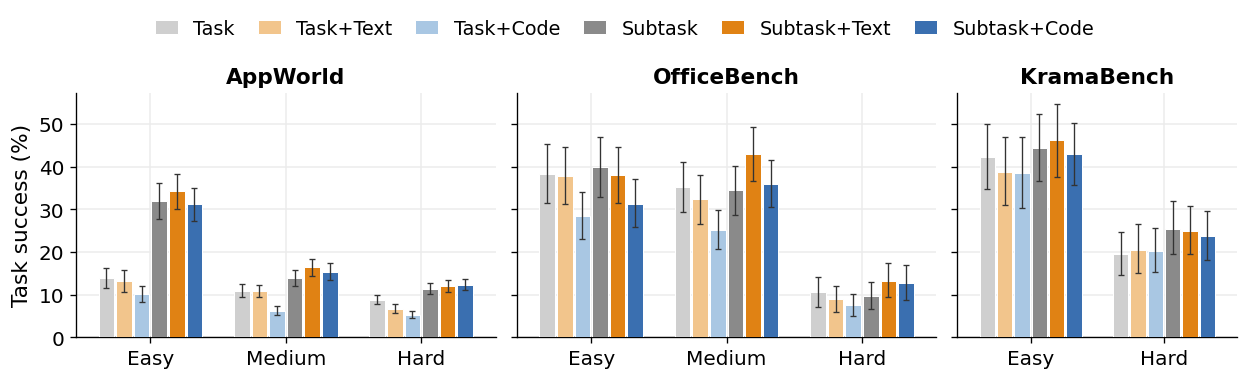

appworld     1     awm: lead +21.09  interaction  +2.90
appworld     1     asi: lead +21.09  interaction  +2.90
appworld     2     awm: lead  +5.70  interaction  +2.61
appworld     2     asi: lead  +9.21  interaction  +6.12
appworld     3     awm: lead  +5.41  interaction  +2.89
appworld     3     asi: lead  +6.99  interaction  +4.48
officebench  1     awm: lead  +0.20  interaction  -1.27
officebench  1     asi: lead  +2.83  interaction  +1.37
officebench  2     awm: lead +10.62  interaction +11.48
officebench  2     asi: lead +10.62  interaction +11.48
officebench  3     awm: lead  +4.38  interaction  +5.28
officebench  3     asi: lead  +5.19  interaction  +6.09
kramabench   easy  awm: lead  +7.30  interaction  +5.17
kramabench   easy  asi: lead  +4.33  interaction  +2.19
kramabench   hard  awm: lead  +4.41  interaction  -1.47
kramabench   hard  asi: lead  +3.52  interaction  -2.36


In [12]:
# Fig q5_success_by_difficulty (fig:difficulty): success by official difficulty stratum for all six conditions, pooled over fully completed models, 95% task-bootstrap CIs.
import os, pickle, json, time
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 13, 'axes.titlesize': 14, 'axes.labelsize': 13,
    'xtick.labelsize': 12, 'ytick.labelsize': 12, 'legend.fontsize': 11.5,
    'figure.dpi': 120, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#ececec', 'grid.linewidth': 0.9,
})
DATA_DIR = f'./{FOLDER}'
FIG_DIR = '../figures' if DATA_DIR.startswith('./') else 'figures'; os.makedirs(FIG_DIR, exist_ok=True)
BENCH_TOKENS = ['appworld', 'officebench', 'kramabench']
MODELS = ['qwen-3-235b-a22b-amazon', 'gpt-oss-120b-amazon', 'nemotron-3-super-120b-amazon',
          'qwen-3-4b-local', 'qwen-3-8b-local', 'qwen-3-14b-local', 'qwen-3-32b-local',
          'gemma-3-4b-local', 'gemma-3-12b-local', 'gemma-3-27b-local', 'gemini-3.1-pro-gcp']
CONDS = ['linear', 'linear_awm', 'linear_asi', 'subtask', 'subtask_awm', 'subtask_asi']
#         label,          cond,          color,     offset
SERIES = [('Task',        'linear',      '#cfcfcf', -0.325),
          ('Task+Text',   'linear_awm',  '#f2c58c', -0.195),
          ('Task+Code',   'linear_asi',  '#a9c7e3', -0.065),
          ('Subtask',       'subtask',     '#8a8a8a',  0.065),
          ('Subtask+Text',  'subtask_awm', '#e08214',  0.195),
          ('Subtask+Code',  'subtask_asi', '#3a6fb0',  0.325)]
REPS, RNG = 10000, np.random.default_rng(0)

AW_TASKS = os.path.expanduser(os.environ.get('APPWORLD_TASKS_DIR', '../external/appworld-data/data/tasks'))
_aw = {t: str(json.load(open(f'{AW_TASKS}/{t}/ground_truth/metadata.json'))['difficulty'])
       for t in COMMON['appworld']}
DIFF_FN = {
    'appworld':    lambda t: _aw[t],
    'officebench': lambda t: t.split('-')[0],
    'kramabench':  lambda t: 'hard' if '-hard-' in t else 'easy',
}
BENCH_NAMES = {'appworld': 'AppWorld', 'officebench': 'OfficeBench', 'kramabench': 'KramaBench'}
LEVELS = {'appworld': [('1', 'Easy'), ('2', 'Medium'), ('3', 'Hard')],
          'officebench': [('1', 'Easy'), ('2', 'Medium'), ('3', 'Hard')],
          'kramabench': [('easy', 'Easy'), ('hard', 'Hard')]}


def _score(r):
    return (r.get('eval_extras') or {}).get('score', 1.0 if r.get('success') else 0.0)


def _read(p, tries=3):
    """Load a pkl; returns None for missing or unreadable files (retries transient NFS errors)."""
    for k in range(tries):
        try:
            with open(p, 'rb') as f:
                return pickle.load(f)
        except FileNotFoundError:
            return None
        except (OSError, EOFError, pickle.UnpicklingError) as e:
            if k == tries - 1:
                print(f'  ! treating as in-flight: {os.path.basename(p)} ({e})')
                return None
            time.sleep(1.0)


# SC[(bench, cond, model)] = {task: score}; a model pools only if complete
SC = {}
for B in BENCH_TOKENS:
    for c in CONDS:
        for M in MODELS:
            r = _read(f'{DATA_DIR}/{B}_{c}_{M}_{STAGE}.pkl')
            if r is None:
                SC[(B, c, M)] = None; continue
            r = list(r.values()) if isinstance(r, dict) else r
            SC[(B, c, M)] = {x['task_id']: _score(x) for x in r
                             if not x.get('errored') and x['task_id'] in COMMON[B]}

POOL = [M for M in MODELS
        if all(SC[(B, c, M)] is not None and len(SC[(B, c, M)]) == len(COMMON[B])
               for B in BENCH_TOKENS for c in CONDS)]
print(f'pooled models ({len(POOL)}/{len(MODELS)}):', POOL)


def _boot(v):
    idx = RNG.integers(0, len(v), (REPS, len(v)))
    m = v[idx].mean(1)
    return 100*v.mean(), 100*np.percentile(m, 2.5), 100*np.percentile(m, 97.5)


w = 0.115
fig, axes = plt.subplots(1, 3, figsize=(10.6, 2.9), sharey=True, width_ratios=[3, 3, 2])
for ax, B in zip(axes, BENCH_TOKENS):
    strata = {lv: [t for t in sorted(COMMON[B]) if DIFF_FN[B](t) == lv] for lv, _ in LEVELS[B]}
    for lab, cond, col, dx in SERIES:
        vals, errs = [], []
        for lv, _ in LEVELS[B]:
            v = np.mean([[SC[(B, cond, M)][t] for t in strata[lv]] for M in POOL], 0)
            mu, lo, hi = _boot(v)
            vals.append(mu); errs.append([mu - lo, hi - mu])
        x = np.arange(len(vals))
        ax.bar(x + dx, vals, w, color=col, edgecolor='white', linewidth=0.6,
               yerr=np.array(errs).T, capsize=1.8,
               error_kw=dict(ecolor='#333', elinewidth=0.8, capthick=0.8), label=lab, zorder=3)
    ax.set_xticks(np.arange(len(LEVELS[B]))); ax.set_xticklabels([lab for _, lab in LEVELS[B]])
    ax.set_xlim(-0.55, len(LEVELS[B]) - 0.45)
    ax.set_title(BENCH_NAMES[B], fontsize=13, fontweight='bold')
axes[0].set_ylabel('Task success (%)')
axes[0].set_ylim(0, None)
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', ncol=6,
           frameon=False, bbox_to_anchor=(0.5, 1.12), columnspacing=1.2, handlelength=1.2)
fig.tight_layout(w_pad=0.7)
fig.savefig(f'{FIG_DIR}/q5_success_by_difficulty.png'); fig.savefig(f'{FIG_DIR}/q5_success_by_difficulty.pdf')
plt.show()

# stratum-level checks for the prose
for B in BENCH_TOKENS:
    strata = {lv: [t for t in sorted(COMMON[B]) if DIFF_FN[B](t) == lv] for lv, _ in LEVELS[B]}
    for lv, _ in LEVELS[B]:
        m = {c: np.mean([[SC[(B, c, M)][t] for t in strata[lv]] for M in POOL]) * 100 for c in CONDS}
        for fam in ('awm', 'asi'):
            lead = m[f'subtask_{fam}'] - m[f'linear_{fam}']
            inter = (m[f'subtask_{fam}'] - m['subtask']) - (m[f'linear_{fam}'] - m['linear'])
            print(f'{B:12s} {lv:5s} {fam}: lead {lead:+6.2f}  interaction {inter:+6.2f}')

## Figure `iclr_skill_quality` (`fig:score-quality`)

**Skill utility = specificity x abstractness**, computed from skills and task instructions alone under the retrieval embedder (all-MiniLM-L6-v2).

For a skill with description embedding $s$ and cosine similarities $c_i$ to all task instructions: specificity is the probability that the skill's best-matching task beats a random task-pair similarity; abstractness is the effective fraction of tasks the skill stays relevant to, $\exp(H(\mathrm{softmax}(c/0.1)))/N$. Utility predicts task success monotonically; either dimension alone does not.

In [ ]:
# Fig iclr_skill_quality (fig:score-quality): skill utility (specificity x abstractness) headline figure. Embeddings are memoized in results/_embcache_final_v1.pkl; the sentence-transformer model is loaded only on a cache miss.
import os, pickle, math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import Image, display

FOLDER = 'results'; STAGE = 'final_v1'
DATA_DIR = f'./{FOLDER}'; FIG_DIR = '../figures'; os.makedirs(FIG_DIR, exist_ok=True)
BENCHES = [('AppWorld','appworld'), ('OfficeBench','officebench'), ('KramaBench','kramabench')]
MODELS  = [('Qwen3-235B','qwen-3-235b-a22b-amazon'), ('Nemotron-120B','nemotron-3-super-120b-amazon'),
           ('GPT-OSS-120B','gpt-oss-120b-amazon'), ('Qwen3-32B','qwen-3-32b-local'),
           ('Qwen3-14B','qwen-3-14b-local'), ('Qwen3-8B','qwen-3-8b-local'),
           ('Qwen3-4B','qwen-3-4b-local'), ('Gemma3-27B','gemma-3-27b-local'),
           ('Gemma3-12B','gemma-3-12b-local'), ('Gemma3-4B','gemma-3-4b-local'),
           ('Gemini-3.1-Pro','gemini-3.1-pro-gcp')]
FAMS = ['awm','asi']; CONDS = ['linear','linear_awm','linear_asi','subtask','subtask_awm','subtask_asi']
EMB_NAME='all-MiniLM-L6-v2'; CACHE_FILE=f'{DATA_DIR}/_embcache_final_v1.pkl'
FIG_BASE='iclr_skill_quality'
METRIC_LABEL='skill utility'

# ── loaders ─────────────────────────────────────────────────────────────────
def _pth(B,c,M,mem=False): return f"{DATA_DIR}/{B}_{c}_{M}_{STAGE}{'_memory' if mem else ''}.pkl"
def load(B,c,M):
    p=_pth(B,c,M)
    if not os.path.exists(p): return []
    r=pickle.load(open(p,'rb')); r=list(r.values()) if isinstance(r,dict) else r
    return [x for x in r if not x.get('errored')]
def skills(B,c,M):
    p=_pth(B,c,M,True)
    return (pickle.load(open(p,'rb')) if os.path.exists(p) else {}).get('skills') or []
def score(r): return (r.get('eval_extras') or {}).get('score', 1.0 if r.get('success') else 0.0)
_EX=('EXAMPLE','illustrative trajectory','reference examples')
def task_instr(r):
    users=[m['content'] for m in (r.get('final_history') or []) if m.get('role')=='user' and m.get('content')]
    real=None; seen=False
    for u in users:
        if 'END OF ALL EXAMPLES' in u: seen=True; continue
        if seen and not any(k in u for k in _EX): real=u; break
    if real is None:
        for u in users:
            if not any(k in u for k in _EX): real=u; break
    if real is None: return None
    c=real
    if 'Task:' in c: c=c.split('Task:',1)[1]
    for s in ('Current Progress','\n\nYou have access','Available tools','In `run_code`'):
        if s in c: c=c.split(s,1)[0]
    return c.strip()[:500]
def instr_map(B,M):
    out={}
    for c in CONDS:
        for r in load(B,c,M):
            if r['task_id'] in out: continue
            ti=task_instr(r)
            if ti: out[r['task_id']]=ti
    return out

# ── embeddings: disk-cached; misses embedded live and written back ────────────
os.environ.setdefault('HF_HOME', os.path.expanduser('~/.cache/huggingface'))
os.environ.setdefault('TOKENIZERS_PARALLELISM','false')
_MODEL=None; _EMB=pickle.load(open(CACHE_FILE,'rb')) if os.path.exists(CACHE_FILE) else {}
_NEW=[0]
def _model():
    global _MODEL
    if _MODEL is None:
        import torch
        from sentence_transformers import SentenceTransformer
        _MODEL=SentenceTransformer(EMB_NAME, device='cuda' if torch.cuda.is_available() else 'cpu')
    return _MODEL
def emb(texts):
    texts=list(texts); todo=[t for t in texts if t not in _EMB]
    if todo:
        uq=list(dict.fromkeys(todo))
        for t,v in zip(uq,_model().encode(uq,normalize_embeddings=True,batch_size=128)):
            _EMB[t]=np.asarray(v,dtype=np.float32)
        _NEW[0]+=len(uq)
    return np.array([_EMB[t] for t in texts])

# ── the score and its two components ─────────────────────────────────────────
TAU=0.1
def skill_metric(c,pairs_sorted):
    """returns (specificity, abstractness, skill utility=product)"""
    z=c/TAU; z=z-z.max(); p=np.exp(z); p/=p.sum()
    abstractness=math.exp(-float(np.sum(p*np.log(np.maximum(p,1e-12)))))/len(c)
    mx=max(float(c.max()),0.0)
    specificity=float(np.searchsorted(pairs_sorted,mx,side='right'))/len(pairs_sorted)
    return (specificity,abstractness,specificity*abstractness)

SCORES={}   # (B,M) -> desc -> (spec, abst, utility)
for _,B in BENCHES:
    for _,M in MODELS:
        im=instr_map(B,M); ids=list(im)
        if not ids: continue
        TI=emb([im[t] for t in ids])
        pairs=np.sort((TI@TI.T)[np.triu_indices(len(ids),1)]) if len(ids)>1 else np.array([0.3])
        allsk=[]
        for fam in FAMS:
            for lvl in ('linear','subtask'): allsk+=skills(B,f'{lvl}_{fam}',M)
        descs=list(dict.fromkeys((s.get('description') or '')[:500] for s in allsk if s.get('description')))
        if not descs: continue
        C=emb(descs)@TI.T
        SCORES[(B,M)]={d:skill_metric(c,pairs) for d,c in zip(descs,C)}
if _NEW[0]: pickle.dump(_EMB,open(CACHE_FILE,'wb'))

def key2desc(B,M):
    sd=SCORES.get((B,M))
    if not sd: return {}
    k={}; allsk=[]
    for fam in FAMS:
        for lvl in ('linear','subtask'): allsk+=skills(B,f'{lvl}_{fam}',M)
    for s in allsk:
        d=(s.get('description') or '')[:500]
        if d not in sd: continue
        k[s['id']]=d; k[d]=d
        nm=(s.get('extra') or {}).get('name')
        if nm: k[nm]=d
    return k

# numpy-only Spearman (+ asymptotic p)
def _rank(x):
    x=np.asarray(x,float); order=x.argsort(); r=np.empty(len(x)); r[order]=np.arange(len(x))
    s=x[order]; i=0
    while i<len(s):
        j=i
        while j+1<len(s) and s[j+1]==s[i]: j+=1
        if j>i: r[order[i:j+1]]=(i+j)/2.0
        i=j+1
    return r+1
def spearman(x,y):
    x=np.asarray(x,float); y=np.asarray(y,float); n=len(x)
    if n<3: return float('nan'),float('nan'),n
    rho=float(np.corrcoef(_rank(x),_rank(y))[0,1])
    z=abs(rho)*math.sqrt(max(n-1,1)); p=math.erfc(z/math.sqrt(2))
    return rho,p,n

# ── run-level records: (benchmark, arm, spec, abst, utility of retrieved, score)
recs=[]
for _,B in BENCHES:
    for _,M in MODELS:
        k2d=key2desc(B,M); sd=SCORES.get((B,M))
        if not k2d: continue
        for fam in FAMS:
            for lvl in ('linear','subtask'):
                for r in load(B,f'{lvl}_{fam}',M):
                    ds=[k2d[x] if x in k2d else k2d.get(x[:500]) for x in (r.get('retrieved_skill_ids') or [])
                        if (x in k2d or x[:500] in k2d)]
                    ds=[d for d in ds if d]
                    if not ds: continue
                    vals=np.array([sd[d] for d in ds])
                    recs.append((B,lvl,float(vals[:,0].mean()),float(vals[:,1].mean()),
                                 float(vals[:,2].mean()),score(r)))

def tert(ix,lvl,k=5):
    """Per-benchmark equal-size k-quantile bins of metric column ix within an arm; point = (mean metric, mean success) averaged over benchmarks, plus n."""
    xs=[[] for _ in range(k)]; ys=[[] for _ in range(k)]; ns=[0]*k
    for _,B in BENCHES:
        g=[(r[2+ix],r[5]) for r in recs if r[0]==B and r[1]==lvl]
        if len(g)<50: continue
        qs=np.quantile([a for a,_ in g],np.linspace(0,1,k+1)); qs[-1]+=1e-9
        for t in range(k):
            gg=[(a,s) for a,s in g if qs[t]<=a<qs[t+1]]
            if gg:
                xs[t].append(np.mean([a for a,_ in gg])); ys[t].append(np.mean([s for _,s in gg]))
                ns[t]+=len(gg)
    return ([float(np.mean(x)) for x in xs],[float(np.mean(y)) for y in ys],ns)

# validation stats for the caption (benchmark-z within arm)
NAMES=['specificity','abstractness','skill utility']
for ix,name in enumerate(NAMES):
    out=[]
    for lvl in ('linear','subtask'):
        Z=[]
        for _,B in BENCHES:
            sub=[(r[2+ix],r[5]) for r in recs if r[0]==B and r[1]==lvl]
            if len(sub)<30: continue
            v=np.array([a for a,_ in sub])
            Z+=[((a-v.mean())/(v.std() or 1),s) for a,s in sub]
        rho,p,n=spearman([a for a,_ in Z],[s for _,s in Z])
        out.append(f'{lvl}: rho={rho:+.3f} (p={p:.1e})')
    print(f'[{name:15s}] '+' | '.join(out))

def lib_utility(B,c,M):
    sd=SCORES.get((B,M))
    if not sd: return float('nan')
    ds=list(dict.fromkeys((s.get('description') or '')[:500] for s in skills(B,c,M) if s.get('description')))
    xs=[sd[d][2] for d in ds if d in sd]
    return float(np.median(xs)) if xs else float('nan')

comp={(B,fam,lvl):[lib_utility(B,f'{lvl}_{fam}',m) for _,m in MODELS]
      for _,B in BENCHES for fam in FAMS for lvl in ('linear','subtask')}
wins=tot=0
for _,B in BENCHES:
    for fam in FAMS:
        for i in range(len(MODELS)):
            l,s=comp[(B,fam,'linear')][i],comp[(B,fam,'subtask')][i]
            if l==l and s==s: tot+=1; wins+= s>l
print(f"[COMPARISON] subtask higher skill utility in {wins}/{tot} cells")

# ──────────────────────────────── FIGURE (1x5) ───────────────────────────────
plt.rcParams.update({'font.size':12,'axes.titlesize':12.5,'axes.labelsize':12,
    'xtick.labelsize':11,'ytick.labelsize':10.5,'legend.fontsize':9,
    'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':120,
    'savefig.dpi':200,'savefig.bbox':'tight'})
TEXT_C,CODE_C='#e08214','#3a6fb0'
LIN_C,SUB_C='#9A9A9A','#222222'

fig,axes=plt.subplots(1,5,figsize=(12.6,2.7),gridspec_kw={'width_ratios':[1.15,1.15,1,1,1],'wspace':0.55})
# (a) success vs skill utility (solid, 95% CI, 1-decimal)
ax=axes[0]
for lvl,col,lab in (('linear',LIN_C,'Task'),('subtask',SUB_C,'Subtask')):
    xs,ys,ns=tert(2,lvl,4)
    se=[math.sqrt(max(y*(1-y),1e-6)/max(n,1)) for y,n in zip(ys,ns)]
    ax.fill_between(xs,[y-1.96*e for y,e in zip(ys,se)],
                    [y+1.96*e for y,e in zip(ys,se)],color=col,alpha=.15,lw=0,zorder=2)
    ax.plot(xs,ys,color=col,lw=2.6,marker='o',ms=5,label=lab,zorder=3)
    # Subtask labels always ABOVE, Task labels always BELOW -> never touch a line
    dy = 11 if lvl=='subtask' else -15
    va = 'bottom' if lvl=='subtask' else 'top'
    for i,(x,y) in enumerate(zip(xs,ys)):
        # nudge the first Task labels right so they clear the rising curves
        dx = 7 if lvl=='linear' and i < len(xs)-1 else 0
        ax.annotate(f'{y:.1%}',(x,y),textcoords='offset points',
                    xytext=(dx,dy),ha='center',va=va,
                    color=col,fontweight='bold',fontsize=8,zorder=4)
ax.set_xlabel('skill utility'); ax.set_ylabel('task success rate')
ax.set_title('(a) all tasks')
ax.set_ylim(.06,.40); ax.margins(x=.16); ax.grid(alpha=.22)
ax.legend(loc='upper left',frameon=False,handlelength=1.2,borderaxespad=0.1)
# Panel b, ablation: each dimension alone on the subtask arm, 5 quantile bins on the actual dimension values (same binning as panel a, 95% CI bands). Both dimensions are inverted-U; the product in panel a is monotone.
ax=axes[1]
blo,bhi=1.0,0.0
for ix,ls,lab in ((0,(0,(4,2)),'specificity'),(1,(0,(1,1.5)),'abstractness')):
    xs,ys,ns=tert(ix,'subtask',5)
    se=[math.sqrt(max(y*(1-y),1e-6)/max(n,1)) for y,n in zip(ys,ns)]
    lo=[y-1.96*e for y,e in zip(ys,se)]; hi=[y+1.96*e for y,e in zip(ys,se)]
    blo=min(blo,*lo); bhi=max(bhi,*hi)
    ax.fill_between(xs,lo,hi,color=SUB_C,alpha=.12,lw=0,zorder=2)
    ax.plot(xs,ys,color=SUB_C,lw=2.4,ls=ls,marker='o',ms=4.5,label=lab,zorder=3)
ax.legend(loc='lower center',frameon=False,handlelength=1.9,borderaxespad=0.2,fontsize=9)
ax.set_xlabel('specificity or abstractness'); ax.set_ylabel('task success rate')
ax.set_title('(b) each dimension alone')
ax.set_ylim(blo-.015,bhi+.015); ax.margins(x=.06); ax.grid(alpha=.22)
# (c-e) per benchmark: library skill utility, Text vs Code
LETTER='cde'
ymax=max(v for vs in comp.values() for v in vs if v==v)*1.35
for ci,(blab,B) in enumerate(BENCHES):
    ax=axes[ci+2]
    for fam,col,lab in (('awm',TEXT_C,'Text'),('asi',CODE_C,'Code')):
        lv=np.array(comp[(B,fam,'linear')]); sv=np.array(comp[(B,fam,'subtask')])
        m=[np.nanmean(lv),np.nanmean(sv)]
        se=[np.nanstd(lv,ddof=1)/np.sqrt(np.sum(lv==lv)) if np.sum(lv==lv)>1 else 0.0,
            np.nanstd(sv,ddof=1)/np.sqrt(np.sum(sv==sv)) if np.sum(sv==sv)>1 else 0.0]
        top=[m[i]+1.96*se[i] for i in (0,1)]; bot=[m[i]-1.96*se[i] for i in (0,1)]
        ax.fill_between([0,1],bot,top,color=col,alpha=.20,lw=0,zorder=2)
        ax.plot([0,1],m,color=col,lw=2.6,marker='o',ms=6,label=lab,zorder=3)
        for i,xx in enumerate((0,1)):
            if fam=='awm':
                ax.annotate(f'{m[i]:.2f}',(xx,top[i]),textcoords='offset points',xytext=(0,4),
                            ha='center',va='bottom',color=col,fontweight='bold',fontsize=9)
            else:
                ax.annotate(f'{m[i]:.2f}',(xx,bot[i]),textcoords='offset points',xytext=(0,-4),
                            ha='center',va='top',color=col,fontweight='bold',fontsize=9)
    ax.set_xticks([0,1]); ax.set_xticklabels(['Task','Subtask'])
    ax.set_ylim(0,ymax); ax.margins(x=.18)
    ax.set_title(f'({LETTER[ci]}) {blab}')
    ax.grid(axis='y',alpha=.22)
    if ci==0:
        ax.set_ylabel('skill utility')
        ax.legend(loc='upper left',frameon=False,handlelength=1.2,borderaxespad=0.1)
    else:
        ax.set_yticklabels([])

png=f'{FIG_DIR}/{FIG_BASE}.png'
fig.savefig(png); fig.savefig(f'{FIG_DIR}/{FIG_BASE}.pdf')
plt.close(fig); display(Image(png))

## Figure `q6_transfer_heatmaps` (`fig:transfer`)

Cross-task transfer from the provenance logs: the task stream is cut into 50 bins; a cell lights up when a skill induced in bin $i$ is retrieved in a later bin $j$. Transfer density $D$ is the share of ordered bin pairs with at least one induce-then-retrieve transfer.

pooled models (11/11): ['qwen-3-235b-a22b-amazon', 'gpt-oss-120b-amazon', 'nemotron-3-super-120b-amazon', 'qwen-3-4b-local', 'qwen-3-8b-local', 'qwen-3-14b-local', 'qwen-3-32b-local', 'gemma-3-4b-local', 'gemma-3-12b-local', 'gemma-3-27b-local', 'gemini-3.1-pro-gcp']
skipped (incomplete): []
Bin-level transfer rate (% of C(50,2)=1225 bin-pairs), mean over 11 models
  AppWorld    Text  linear   9.3   subtask  37.0
  AppWorld    Code  linear  30.1   subtask  24.7
  OfficeBench Text  linear  18.9   subtask  32.1
  OfficeBench Code  linear  36.5   subtask  46.0
  KramaBench  Text  linear   1.6   subtask  11.1
  KramaBench  Code  linear  10.5   subtask  23.0
Pooled (both formats x 11 models) transfer density:
  AppWorld     linear  19.7   subtask  30.8
  OfficeBench  linear  27.7   subtask  39.0
  KramaBench   linear   6.0   subtask  17.1


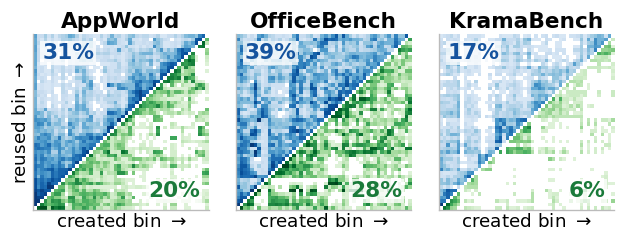

wrote figures/q6_transfer_heatmaps.{png,pdf}


In [14]:
# Fig q6_transfer_heatmaps (fig:transfer): binned induce-then-retrieve transfer heatmaps from the provenance logs, one square per family and benchmark.
import os, pickle, numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

DATA_DIR = 'results'  # relative to data/, where this notebook lives
STAGE = 'final_v1'
NBINS = 50            # square is NBINS×NBINS; bin-level rate denominator = C(NBINS,2)
FIG_DIR = os.path.join(DATA_DIR, '..', 'figures'); os.makedirs(FIG_DIR, exist_ok=True)
BENCHES = [('AppWorld', 'appworld'), ('OfficeBench', 'officebench'), ('KramaBench', 'kramabench')]
ALL_MODELS = ['qwen-3-235b-a22b-amazon', 'gpt-oss-120b-amazon', 'nemotron-3-super-120b-amazon',
              'qwen-3-4b-local', 'qwen-3-8b-local', 'qwen-3-14b-local', 'qwen-3-32b-local',
              'gemma-3-4b-local', 'gemma-3-12b-local', 'gemma-3-27b-local', 'gemini-3.1-pro-gcp']
CONDS = ['linear', 'linear_awm', 'linear_asi', 'subtask', 'subtask_awm', 'subtask_asi']
FAMS = [('Text', 'awm'), ('Code', 'asi')]
GRN, BLU = '#1a7a3a', '#15539e'        # linear=green, subtask=blue


def load(B, c, M):
    p = f'{DATA_DIR}/{B}_{c}_{M}_{STAGE}.pkl'
    if not os.path.exists(p): return []
    r = pickle.load(open(p, 'rb')); r = list(r.values()) if isinstance(r, dict) else r
    return [x for x in r if not x.get('errored')]


def provlog(B, c, M):
    p = f'{DATA_DIR}/{B}_{c}_{M}_{STAGE}_memory.pkl'
    m = pickle.load(open(p, 'rb')) if os.path.exists(p) else None
    return (m or {}).get('provenance_log') or []


def order_index(B, M):
    idx = {}
    for c in ['linear', 'linear_awm', 'linear_asi', 'subtask', 'subtask_awm', 'subtask_asi']:
        for r in load(B, c, M): idx.setdefault(r['task_id'], r.get('task_idx'))
    return {t: i for t, i in idx.items() if i is not None}


def fwd_pairs(B, role, M, idx):
    creator, pairs = {}, set()
    for row in provlog(B, role, M):
        t = row['task']
        for s in row.get('retrieved', []) or []:
            c = creator.get(s)
            if c is not None and c != t and c in idx and t in idx and idx[t] > idx[c]:
                pairs.add((idx[c], idx[t]))
        for s in row.get('created', []) or []: creator.setdefault(s, t)
    return pairs


# auto-detect the models whose full grid is complete on the COMMON tasks
def _complete(M):
    for _, B in BENCHES:
        ids = COMMON[B]
        for c in CONDS:
            done = {r['task_id'] for r in load(B, c, M)}
            if not ids <= done:
                return False
    return True
MODELS = [M for M in ALL_MODELS if _complete(M)]
print(f'pooled models ({len(MODELS)}/{len(ALL_MODELS)}):', MODELS)
print('skipped (incomplete):', [M for M in ALL_MODELS if M not in MODELS])

# per-model forward task-idx pairs, per (bench, fam, method); averaged over models below
AGG = {}
for _, B in BENCHES:
    for _, fam in FAMS:
        for meth in ['linear', 'subtask']:
            role = f'{meth}_{fam}'; pm = []
            for M in MODELS:
                idx = order_index(B, M)
                if not idx: continue
                pm.append((fwd_pairs(B, role, M, idx), max(idx.values()) + 1))
            AGG[(B, fam, meth)] = pm

def avg_binmat(B, fam, meth):
    pm = AGG[(B, fam, meth)]
    return np.mean([binmat(p, N, NBINS) for p, N in pm], axis=0) if pm else np.zeros((NBINS, NBINS))
def avg_binrate(B, fam, meth):
    pm = AGG[(B, fam, meth)]
    return float(np.mean([binrate(p, N, NBINS) for p, N in pm])) if pm else 0.0


def _bin(v, N, nb): return min(int(v / N * nb), nb - 1)

def binmat(pairs, N, nb):
    """M[reused_bin, created_bin] = 1 if the model has >=1 transfer in the bin pair, else 0; averaging over models turns this into the model fraction."""
    M = np.zeros((nb, nb))
    for c, t in pairs:
        bc, bt = _bin(c, N, nb), _bin(t, N, nb)
        if bt > bc: M[bt, bc] = 1
    return M

def binrate(pairs, N, nb):
    """% of the C(nb,2) off-diagonal bin-pairs that carry >=1 transfer."""
    s = set()
    for c, t in pairs:
        bc, bt = _bin(c, N, nb), _bin(t, N, nb)
        if bt > bc: s.add((bc, bt))
    return 100 * len(s) / (nb * (nb - 1) / 2)


def trunc(name, lo=0.12):
    b = plt.get_cmap(name)
    return LinearSegmentedColormap.from_list(name + '_t', b(np.linspace(lo, 1, 256)))
BL_cm, GR_cm = trunc('Blues'), trunc('Greens')

print(f'Bin-level transfer rate (% of C({NBINS},2)={int(NBINS*(NBINS-1)/2)} bin-pairs), mean over {len(MODELS)} models')
for blab, B in BENCHES:
    for flab, fam in FAMS:
        short = flab.split(' ·')[0]
        rl = avg_binrate(B, fam, 'linear')
        rs = avg_binrate(B, fam, 'subtask')
        print(f'  {blab:11s} {short:4s}  linear {rl:5.1f}   subtask {rs:5.1f}')

# Figure: 1x3 over benchmarks, formats pooled. Each panel pools both skill formats and all models, showing only the axis reuse frequency faithfully tracks (Subtask vs Task-level); format is deliberately not split since code skills are retrieved as often as text yet help less.
plt.rcParams.update({'font.size': 12, 'savefig.bbox': 'tight', 'font.family': 'DejaVu Sans'})


def binmat_g(B, meth):
    mats = [binmat(p, N, NBINS) for _, fam in FAMS for p, N in AGG[(B, fam, meth)]]
    return np.mean(mats, axis=0) if mats else np.zeros((NBINS, NBINS))


def binrate_g(B, meth):
    rs = [binrate(p, N, NBINS) for _, fam in FAMS for p, N in AGG[(B, fam, meth)]]
    return float(np.mean(rs)) if rs else 0.0


print(f'Pooled (both formats x {len(MODELS)} models) transfer density:')
for blab, B in BENCHES:
    print(f'  {blab:11s}  linear {binrate_g(B, "linear"):5.1f}   subtask {binrate_g(B, "subtask"):5.1f}')

fig, axes = plt.subplots(1, 3, figsize=(5.4, 2.15))
for cj, (blab, B) in enumerate(BENCHES):
    ax = axes[cj]
    S = binmat_g(B, 'subtask'); L = binmat_g(B, 'linear')
    rs = binrate_g(B, 'subtask'); rl = binrate_g(B, 'linear')
    Lt = np.zeros_like(L)                          # linear transposed into lower-right triangle
    for u in range(NBINS):
        for c in range(NBINS):
            if L[u, c] > 0: Lt[c, u] = L[u, c]
    ax.imshow(np.ma.masked_equal(S, 0), cmap=BL_cm, vmin=0, vmax=1,
              origin='lower', extent=[0, NBINS, 0, NBINS], interpolation='nearest', aspect='auto')
    ax.imshow(np.ma.masked_equal(Lt, 0), cmap=GR_cm, vmin=0, vmax=1,
              origin='lower', extent=[0, NBINS, 0, NBINS], interpolation='nearest', aspect='auto')
    ax.set_box_aspect(1)
    ax.set_xlim(0, NBINS); ax.set_ylim(0, NBINS)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_edgecolor('#bbbbbb')
    ax.text(0.05, 0.95, f'{rs:.0f}%', color=BLU, fontsize=13, fontweight='bold',
            transform=ax.transAxes, va='top', ha='left',
            bbox=dict(fc='white', alpha=0.75, ec='none', pad=1))
    ax.text(0.95, 0.05, f'{rl:.0f}%', color=GRN, fontsize=13, fontweight='bold',
            transform=ax.transAxes, va='bottom', ha='right',
            bbox=dict(fc='white', alpha=0.75, ec='none', pad=1))
    ax.set_title(blab, fontsize=13, fontweight='bold', pad=4)
    ax.set_xlabel('created bin $\\rightarrow$', fontsize=11, labelpad=2)
    if cj == 0:
        ax.set_ylabel('reused bin $\\rightarrow$', fontsize=11, labelpad=2)
fig.subplots_adjust(left=0.085, right=0.995, top=0.85, bottom=0.17, wspace=0.10)
fig.savefig(f'{FIG_DIR}/q6_transfer_heatmaps.png', dpi=200, bbox_inches='tight')
fig.savefig(f'{FIG_DIR}/q6_transfer_heatmaps.pdf', bbox_inches='tight'); plt.show()
print('wrote figures/q6_transfer_heatmaps.{png,pdf}')

# Appendix figures

## Figure `q8_linear_subskills` (`fig:linear-subskills`, App D.1)

Memory swap: the task-level agent replays the subtask-level agent's frozen skill library at retrieval time (Qwen3-235B-A22B and GPT-OSS-120B, both formats). Shows the granularity effect travels with the skills, not the agent loop.

appworld: common N = 417
officebench: common N = 300
kramabench: common N = 92


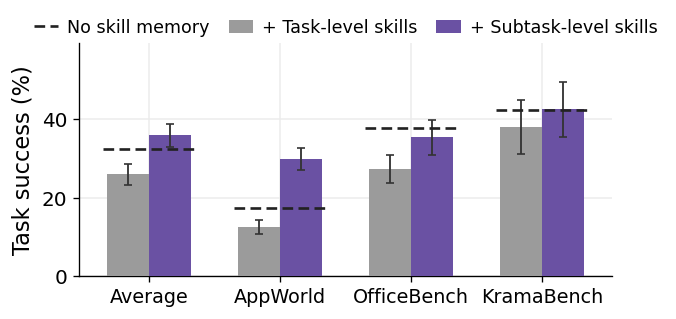

Average      original  26.0   subtask-skills  35.9   Δ(swap-orig)  +9.9   no-memory  32.4   Δ(swap-none)  +3.4
AppWorld     original  12.6   subtask-skills  29.8   Δ(swap-orig) +17.2   no-memory  17.4   Δ(swap-none) +12.4
OfficeBench  original  27.3   subtask-skills  35.3   Δ(swap-orig)  +8.0   no-memory  37.7   Δ(swap-none)  -2.3
KramaBench   original  37.9   subtask-skills  42.4   Δ(swap-orig)  +4.5   no-memory  42.3   Δ(swap-none)  +0.2


In [9]:
# Fig q8_linear_subskills (fig:linear-subskills, App D.1): task-level agent replaying the subtask agent's frozen skill memory (memory swap).
import os, pickle, time
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 13, 'axes.titlesize': 14.5, 'axes.labelsize': 13.5,
    'xtick.labelsize': 11.5, 'ytick.labelsize': 12, 'legend.fontsize': 10.5,
    'figure.dpi': 120, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#ececec', 'grid.linewidth': 0.9,
})
DATA_DIR = f"./{globals().get('FOLDER', '.')}"
FIG_DIR = '../figures' if DATA_DIR.startswith('./') else 'figures'; os.makedirs(FIG_DIR, exist_ok=True)
BENCHES = [('AppWorld', 'appworld'), ('OfficeBench', 'officebench'), ('KramaBench', 'kramabench')]
SWAP_MODELS = ['qwen-3-235b-a22b-amazon', 'gpt-oss-120b-amazon']
FMTS = ['awm', 'asi']                      # Text / Code, averaged in this figure
ORIG_C, SWAP_C, NONE_C = '#9b9b9b', '#6a51a3', '#222222'
REPS, RNG = 10000, np.random.default_rng(0)


def _read(p, tries=3):
    for k in range(tries):
        try:
            with open(p, 'rb') as f:
                return pickle.load(f)
        except FileNotFoundError:
            return None
        except (OSError, EOFError, pickle.UnpicklingError) as e:
            if k == tries - 1:
                print(f'  ! unreadable: {os.path.basename(p)} ({e})'); return None
            time.sleep(1.0)


def _scores(B, cond, M, stage):
    r = _read(f'{DATA_DIR}/{B}_{cond}_{M}_{stage}.pkl')
    if r is None:
        return None
    r = list(r.values()) if isinstance(r, dict) else r
    return {x['task_id']: (x.get('eval_extras') or {}).get(
                'score', 1.0 if x.get('success') else 0.0)
            for x in r if not x.get('errored')}


# Per benchmark: all cells that enter the figure, on their common task subset.
V = {}                                    # V[B] = dict of pooled per-task vectors
for _, B in BENCHES:
    cells = {}
    for M in SWAP_MODELS:
        cells[('none', M)] = _scores(B, 'linear', M, 'final_v1')
        for f in FMTS:
            cells[('orig', M, f)] = _scores(B, f'linear_{f}', M, 'final_v1')
            cells[('swap', M, f)] = _scores(B, f'linear_{f}', M, 'subskill_v1')
    assert all(v for v in cells.values()), f'{B}: missing cells'
    ids = sorted(set.intersection(*[set(v) for v in cells.values()]))
    print(f'{B}: common N = {len(ids)}')
    V[B] = {
        'orig': np.array([[cells[('orig', M, f)][t] for t in ids]
                          for M in SWAP_MODELS for f in FMTS]).mean(0),
        'swap': np.array([[cells[('swap', M, f)][t] for t in ids]
                          for M in SWAP_MODELS for f in FMTS]).mean(0),
        'none': np.array([[cells[('none', M)][t] for t in ids]
                          for M in SWAP_MODELS]).mean(0),
    }


def _boot(vs):
    boots = []
    for v in vs:
        idx = RNG.integers(0, len(v), (REPS, len(v)))
        boots.append(v[idx].mean(1))
    m = np.mean(boots, 0)
    return 100*np.mean([v.mean() for v in vs]), 100*np.percentile(m, 2.5), 100*np.percentile(m, 97.5)


ST = {(Bn, c): _boot([V[B][c]]) for Bn, B in BENCHES for c in ('orig', 'swap', 'none')}
for c in ('orig', 'swap', 'none'):
    ST[('Average', c)] = _boot([V[B][c] for _, B in BENCHES])

GROUPS = ['Average'] + [b for b, _ in BENCHES]
W = 0.32
fig, ax = plt.subplots(figsize=(5.8, 2.9))
for k, (c, col, lab) in enumerate([
        ('orig', ORIG_C, '+ Task-level skills'),
        ('swap', SWAP_C, '+ Subtask-level skills')]):
    xs = [i + (k - 0.5) * W for i in range(len(GROUPS))]
    pts = [ST[(G, c)] for G in GROUPS]
    ax.bar(xs, [p[0] for p in pts], W, color=col, label=lab, zorder=3)
    ax.errorbar(xs, [p[0] for p in pts],
                yerr=[[p[0] - p[1] for p in pts], [p[2] - p[0] for p in pts]],
                fmt='none', ecolor='#333333', elinewidth=1.1, capsize=2.5, zorder=4)
for i, G in enumerate(GROUPS):
    ax.hlines(ST[(G, 'none')][0], i - 0.5 * W - W / 2 - 0.03, i + 0.5 * W + W / 2 + 0.03,
              color=NONE_C, ls=(0, (4, 2)), lw=1.6, zorder=5,
              label='No skill memory' if i == 0 else None)
ax.set_xticks(range(len(GROUPS))); ax.set_xticklabels(GROUPS)
ax.set_ylabel('Task success (%)')
ax.set_ylim(0, 1.18 * max(hi for _, _, hi in ST.values()))
ax.legend(loc='upper center', ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.17),
          columnspacing=1.1, handlelength=1.4, handletextpad=0.5)
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/q8_linear_subskills.png'); fig.savefig(f'{FIG_DIR}/q8_linear_subskills.pdf')
plt.show()

# Numbers for the prose (format-averaged, model-pooled).
for G in GROUPS:
    o, s, n = (ST[(G, c)][0] for c in ('orig', 'swap', 'none'))
    print(f'{G:12s} original {o:5.1f}   subtask-skills {s:5.1f}   Δ(swap-orig) {s-o:+5.1f}   '
          f'no-memory {n:5.1f}   Δ(swap-none) {s-n:+5.1f}')

## Figure `q6_prompt_ablation` (`fig:prompt-ablation`, App D)

Induction-prompt component ladder: L1 minimal instruction, L2 adds one demonstration, L3 is the deployed full prompt (3 MoE models + Qwen3-32B).

models averaged per point (min..max): 4 .. 11
per level: {'L1': [4], 'L2': [4], 'L3': [11]}
Claim1 (subtask+skill > linear+skill): 18/18 above diagonal
Claim2 (subtaskD > linearD):           15/18 above diagonal; 13/18 upper-left


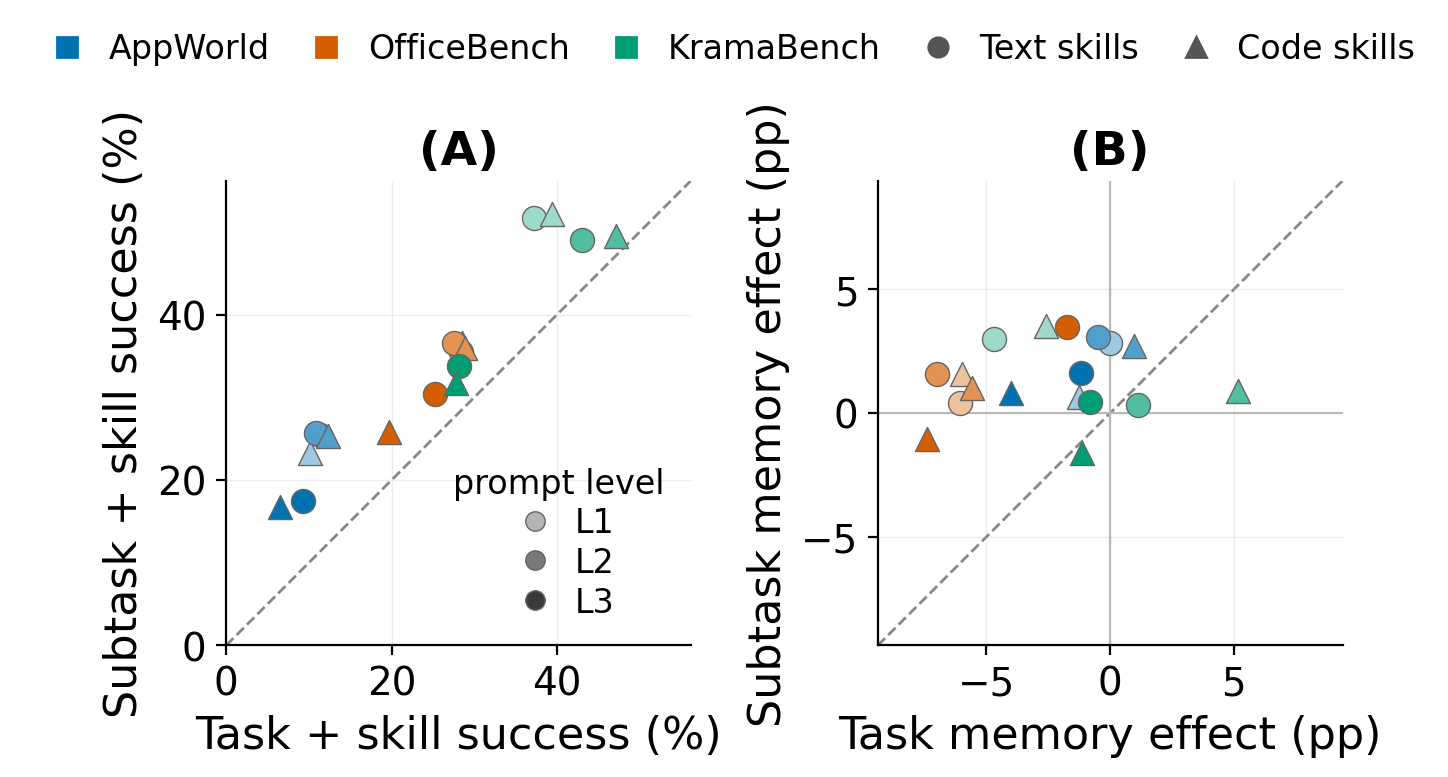

In [ ]:
# Fig q6_prompt_ablation (fig:prompt-ablation, App D): induction-prompt component ladder (L1 minimal / L2 +demonstration / L3 deployed), 3 MoE models + Qwen3-32B.
import os, pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from IPython.display import Image, display
from collections import defaultdict

DATA_DIR = 'results'
FIG_DIR = '../figures'; os.makedirs(FIG_DIR, exist_ok=True)
BENCHES = [('appworld', 'AppWorld'), ('officebench', 'OfficeBench'), ('kramabench', 'KramaBench')]
LEVELS = [('L1', 'prompt_abl2_L1'), ('L2', 'prompt_abl2_L2'), ('L3', 'final_v1')]
FAMS = [('awm', 'Text'), ('asi', 'Code')]
# every model we test; a point uses whichever of these actually ran it
ALL_MODELS = ['qwen-3-235b-a22b-amazon', 'gpt-oss-120b-amazon', 'nemotron-3-super-120b-amazon',
              'qwen-3-4b-local', 'qwen-3-8b-local', 'qwen-3-14b-local', 'qwen-3-32b-local',
              'gemma-3-4b-local', 'gemma-3-12b-local', 'gemma-3-27b-local', 'gemini-3.1-pro-gcp']

def _pth(b, c, M, S): return f"{DATA_DIR}/{b}_{c}_{M}_{S}.pkl"
_RC = {}
def load(b, c, M, S):
    k = (b, c, M, S)
    if k not in _RC:
        p = _pth(b, c, M, S)
        _RC[k] = [x for x in pickle.load(open(p, 'rb')) if not x.get('errored')] if os.path.exists(p) else []
    return _RC[k]
def score(r): return (r.get('eval_extras') or {}).get('score', 1.0 if r.get('success') else 0.0)
def succ_on(b, c, M, S, common):
    rr = [score(r) for r in load(b, c, M, S) if r['task_id'] in common]
    return float(np.mean(rr)) if rr else float('nan')

# Per (bench, level, format): collect (linear+skill, subtask+skill) and the two memory effects, one tuple per model that ran the point, then average.
A = defaultdict(list); Bd = defaultdict(list); NMOD = {}
for b, blab in BENCHES:
    for Llab, S in LEVELS:
        for fam, _ in FAMS:
            n = 0
            for M in ALL_MODELS:
                runs = [load(b, f'linear_{fam}', M, S), load(b, f'subtask_{fam}', M, S),
                        load(b, 'linear', M, 'final_v1'), load(b, 'subtask', M, 'final_v1')]
                sets = [{r['task_id'] for r in rr} for rr in runs]
                if not all(sets):
                    continue
                common = set.intersection(*sets)
                if not common:
                    continue
                lin = succ_on(b, f'linear_{fam}', M, S, common)
                sub = succ_on(b, f'subtask_{fam}', M, S, common)
                lin0 = succ_on(b, 'linear', M, 'final_v1', common)
                sub0 = succ_on(b, 'subtask', M, 'final_v1', common)
                A[(b, Llab, fam)].append((lin, sub))
                Bd[(b, Llab, fam)].append((lin - lin0, sub - sub0))
                n += 1
            NMOD[(b, Llab, fam)] = n

def pts(D):
    out = []
    for (b, Llab, fam), vals in D.items():
        v = np.array(vals); v = v[~np.isnan(v).any(1)]
        if len(v): out.append((b, fam, Llab, float(v[:, 0].mean()), float(v[:, 1].mean()), len(v)))
    return out
PA, PB = pts(A), pts(Bd)
print("models averaged per point (min..max):",
      min(n for *_, n in PA), "..", max(n for *_, n in PA))
print("per level:", {L: sorted({NMOD[(b, L, f)] for b, _ in BENCHES for f, _ in FAMS}) for L, _ in LEVELS})
nA = sum(y > x for *_, x, y, _ in PA); nB = sum(y > x for *_, x, y, _ in PB)
nBnw = sum(x < 0 < y for *_, x, y, _ in PB)
print(f"Claim1 (subtask+skill > linear+skill): {nA}/{len(PA)} above diagonal")
print(f"Claim2 (subtaskD > linearD):           {nB}/{len(PB)} above diagonal; {nBnw}/{len(PB)} upper-left")

plt.rcParams.update({'font.size': 15, 'axes.titlesize': 17, 'axes.labelsize': 16,
    'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
    'savefig.dpi': 300, 'savefig.bbox': 'tight'})
BCOL = {'appworld': '#0072B2', 'officebench': '#D55E00', 'kramabench': '#009E73'}
BLAB = {b: l for b, l in BENCHES}
FMK = {'awm': 'o', 'asi': '^'}
LTint = {'L1': 0.62, 'L2': 0.32, 'L3': 0.0}
def shade(hexc, t):
    rgb = np.array(mcolors.to_rgb(hexc)); return tuple(rgb + (1 - rgb) * t)
SZ = 75
fig, axes = plt.subplots(1, 2, figsize=(6.7, 3.5))

ax = axes[0]
for b, fam, L, x, y, _n in PA:
    ax.scatter(100*x, 100*y, s=SZ, color=shade(BCOL[b], LTint[L]), marker=FMK[fam],
               edgecolors='#666', linewidths=0.5, zorder=3)
hi = max(max(100*y for *_, y, _ in PA), max(100*x for *_, x, _, _ in PA)) + 4
ax.plot([0, hi], [0, hi], ls='--', color='#888', lw=1, zorder=1)
ax.set_xlim(0, hi); ax.set_ylim(0, hi); ax.set_aspect('equal')
ax.set_xlabel('Task + skill success (%)'); ax.set_ylabel('Subtask + skill success (%)')
ax.set_title('(A)', fontweight='bold')
ax.grid(alpha=0.22, lw=0.5)

ax = axes[1]
for b, fam, L, x, y, _n in PB:
    ax.scatter(100*x, 100*y, s=SZ, color=shade(BCOL[b], LTint[L]), marker=FMK[fam],
               edgecolors='#666', linewidths=0.5, zorder=3)
xs = [100*x for *_, x, _, _ in PB] + [100*y for *_, y, _ in PB]
m = max(abs(min(xs)), abs(max(xs))) + 2
ax.plot([-m, m], [-m, m], ls='--', color='#888', lw=1, zorder=1)
ax.axhline(0, color='#bbb', lw=0.8, zorder=1); ax.axvline(0, color='#bbb', lw=0.8, zorder=1)
ax.set_xlim(-m, m); ax.set_ylim(-m, m); ax.set_aspect('equal')
ax.set_xlabel('Task memory effect (pp)'); ax.set_ylabel('Subtask memory effect (pp)')
ax.set_title('(B)', fontweight='bold')
ax.grid(alpha=0.22, lw=0.5)

bh = [Line2D([], [], color=BCOL[b], marker='s', ls='', ms=7, label=BLAB[b]) for b, _ in BENCHES]
mh = [Line2D([], [], color='#555', marker='o', ls='', ms=7, label='Text skills'),
      Line2D([], [], color='#555', marker='^', ls='', ms=7, label='Code skills')]
lh = [Line2D([], [], color=shade('#3a3a3a', LTint[L]), marker='o', ls='', ms=7,
             mec='#666', mew=0.5, label=L) for L in ('L1', 'L2', 'L3')]
fig.legend(handles=bh + mh, loc='upper center', ncol=5, frameon=False,
           bbox_to_anchor=(0.5, 1.09), handletextpad=0.25, columnspacing=0.7)
# prompt-level shade key in panel A's lower-right, which is empty (all points above the diagonal)
axes[0].legend(handles=lh, loc='lower right', frameon=False, title='prompt level',
               fontsize=12, title_fontsize=12, handletextpad=0.2, labelspacing=0.2, borderaxespad=0.4)
fig.tight_layout(rect=(0, 0, 1, 0.93))
png = f'{FIG_DIR}/q6_prompt_ablation.png'
fig.savefig(f'{FIG_DIR}/q6_prompt_ablation.pdf'); fig.savefig(png, dpi=200)
plt.close(fig); display(Image(png))

## Figure `iclr_skill_utility_tradeoff` (`fig:tradeoff`, App D)

Specificity and abstractness trade off across the skill population; deciles of one dimension against the other.

[TRADEOFF] appworld: skill-level spearman(specificity, abstractness) = -0.94 over 9529 skills
[TRADEOFF] officebench: skill-level spearman(specificity, abstractness) = -0.89 over 9697 skills
[TRADEOFF] kramabench: skill-level spearman(specificity, abstractness) = -0.97 over 3766 skills


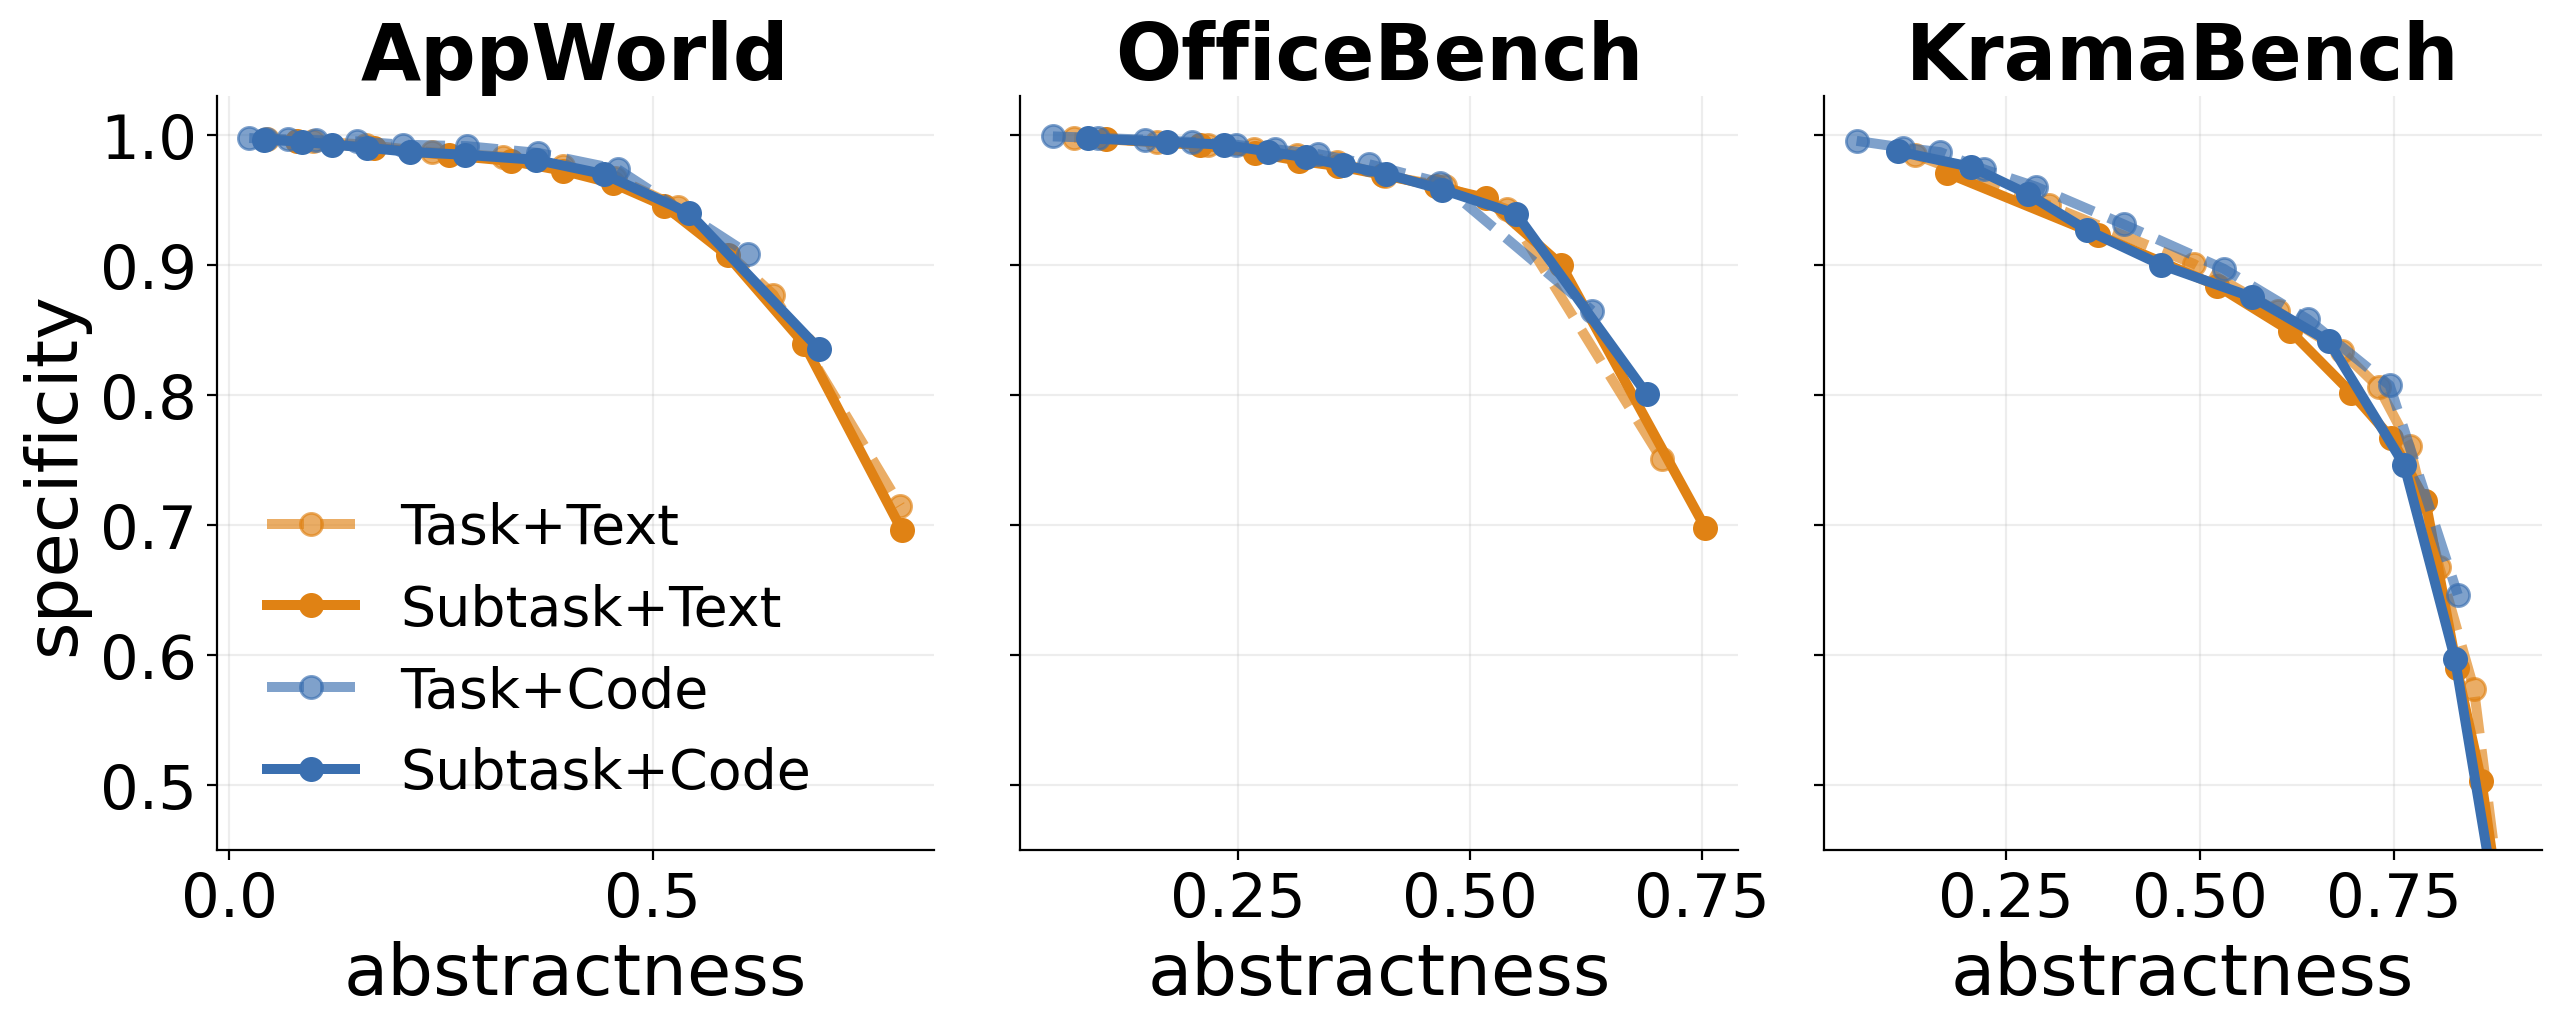

In [ ]:
# Fig iclr_skill_utility_tradeoff (fig:tradeoff, App D): the specificity-abstractness tradeoff inside skill utility.
import os, pickle, math
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

FOLDER = 'results'; STAGE = 'final_v1'
DATA_DIR = f'./{FOLDER}'; FIG_DIR = '../figures'; os.makedirs(FIG_DIR, exist_ok=True)
BENCHES = [('AppWorld','appworld'), ('OfficeBench','officebench'), ('KramaBench','kramabench')]
MODELS  = [('Qwen3-235B','qwen-3-235b-a22b-amazon'), ('Nemotron-120B','nemotron-3-super-120b-amazon'),
           ('GPT-OSS-120B','gpt-oss-120b-amazon'), ('Qwen3-32B','qwen-3-32b-local'),
           ('Qwen3-14B','qwen-3-14b-local'), ('Qwen3-8B','qwen-3-8b-local'),
           ('Qwen3-4B','qwen-3-4b-local'), ('Gemma3-27B','gemma-3-27b-local'),
           ('Gemma3-12B','gemma-3-12b-local'), ('Gemma3-4B','gemma-3-4b-local'),
           ('Gemini-3.1-Pro','gemini-3.1-pro-gcp')]
FAMS = ['awm','asi']; CONDS = ['linear','linear_awm','linear_asi','subtask','subtask_awm','subtask_asi']
EMB_NAME='all-MiniLM-L6-v2'; CACHE_FILE=f'{DATA_DIR}/_embcache_final_v1.pkl'

def _pth(B,c,M,mem=False): return f"{DATA_DIR}/{B}_{c}_{M}_{STAGE}{'_memory' if mem else ''}.pkl"
def load(B,c,M):
    p=_pth(B,c,M)
    if not os.path.exists(p): return []
    r=pickle.load(open(p,'rb')); r=list(r.values()) if isinstance(r,dict) else r
    return [x for x in r if not x.get('errored')]
def skills(B,c,M):
    p=_pth(B,c,M,True)
    return (pickle.load(open(p,'rb')) if os.path.exists(p) else {}).get('skills') or []
_EX=('EXAMPLE','illustrative trajectory','reference examples')
def task_instr(r):
    users=[m['content'] for m in (r.get('final_history') or []) if m.get('role')=='user' and m.get('content')]
    real=None; seen=False
    for u in users:
        if 'END OF ALL EXAMPLES' in u: seen=True; continue
        if seen and not any(k in u for k in _EX): real=u; break
    if real is None:
        for u in users:
            if not any(k in u for k in _EX): real=u; break
    if real is None: return None
    c=real
    if 'Task:' in c: c=c.split('Task:',1)[1]
    for s in ('Current Progress','\n\nYou have access','Available tools','In `run_code`'):
        if s in c: c=c.split(s,1)[0]
    return c.strip()[:500]
def instr_map(B,M):
    out={}
    for c in CONDS:
        for r in load(B,c,M):
            if r['task_id'] in out: continue
            ti=task_instr(r)
            if ti: out[r['task_id']]=ti
    return out

os.environ.setdefault('HF_HOME', os.path.expanduser('~/.cache/huggingface'))
os.environ.setdefault('TOKENIZERS_PARALLELISM','false')
_MODEL=None; _EMB=pickle.load(open(CACHE_FILE,'rb')) if os.path.exists(CACHE_FILE) else {}
_NEW=[0]
def _model():
    global _MODEL
    if _MODEL is None:
        import torch
        from sentence_transformers import SentenceTransformer
        _MODEL=SentenceTransformer(EMB_NAME, device='cuda' if torch.cuda.is_available() else 'cpu')
    return _MODEL
def emb(texts):
    texts=list(texts); todo=[t for t in texts if t not in _EMB]
    if todo:
        uq=list(dict.fromkeys(todo))
        for t,v in zip(uq,_model().encode(uq,normalize_embeddings=True,batch_size=128)):
            _EMB[t]=np.asarray(v,dtype=np.float32)
        _NEW[0]+=len(uq)
    return np.array([_EMB[t] for t in texts])

# ── the two parameter-free components ─────────────────────────────────────────
TAU=0.1
def components(c,pairs_sorted):
    """(specificity, abstractness) for one skill's cosine row c over all N tasks."""
    z=c/TAU; z=z-z.max(); p=np.exp(z); p/=p.sum()
    abstractness=math.exp(-float(np.sum(p*np.log(np.maximum(p,1e-12)))))/len(c)
    mx=max(float(c.max()),0.0)
    specificity=float(np.searchsorted(pairs_sorted,mx,side='right'))/len(pairs_sorted)
    return specificity,abstractness

COMP={}   # (B,M) -> desc -> (specificity, abstractness)
for _,B in BENCHES:
    for _,M in MODELS:
        im=instr_map(B,M); ids=list(im)
        if not ids: continue
        TI=emb([im[t] for t in ids])
        pairs=np.sort((TI@TI.T)[np.triu_indices(len(ids),1)]) if len(ids)>1 else np.array([0.3])
        allsk=[]
        for fam in FAMS:
            for lvl in ('linear','subtask'): allsk+=skills(B,f'{lvl}_{fam}',M)
        descs=list(dict.fromkeys((s.get('description') or '')[:500] for s in allsk if s.get('description')))
        if not descs: continue
        C=emb(descs)@TI.T
        COMP[(B,M)]={d:components(c,pairs) for d,c in zip(descs,C)}
if _NEW[0]: pickle.dump(_EMB,open(CACHE_FILE,'wb'))

def _rank(x):
    x=np.asarray(x,float); order=x.argsort(); r=np.empty(len(x)); r[order]=np.arange(len(x))
    s=x[order]; i=0
    while i<len(s):
        j=i
        while j+1<len(s) and s[j+1]==s[i]: j+=1
        if j>i: r[order[i:j+1]]=(i+j)/2.0
        i=j+1
    return r+1
def spearman(x,y):
    x=np.asarray(x,float); y=np.asarray(y,float)
    return float(np.corrcoef(_rank(x),_rank(y))[0,1])

def combo_skills(B,lvl,fam):
    out=[]
    for _,M in MODELS:
        sd=COMP.get((B,M))
        if not sd: continue
        ds=list(dict.fromkeys((s.get('description') or '')[:500]
              for s in skills(B,f'{lvl}_{fam}',M) if s.get('description')))
        out+=[sd[d] for d in ds if d in sd]
    return out
def decile_curve(pts):
    r=np.array([p[0] for p in pts]); b=np.array([p[1] for p in pts])
    qs=np.quantile(b,np.linspace(0,1,11)); qs[-1]+=1e-9
    xs=[]; ys=[]
    for i in range(10):
        m=(b>=qs[i])&(b<qs[i+1])
        if m.sum(): xs.append(float(b[m].mean())); ys.append(float(r[m].mean()))
    return xs,ys

for _,B in BENCHES:
    pts=[v for (b,M),sd in COMP.items() if b==B for v in sd.values()]
    print(f'[TRADEOFF] {B}: skill-level spearman(specificity, abstractness) = '
          f'{spearman([p[0] for p in pts],[p[1] for p in pts]):+.2f} over {len(pts)} skills')

# ──────────────────────────────── FIGURE (1x3) ───────────────────────────────
plt.rcParams.update({'font.size':25,'axes.titlesize':28,'axes.labelsize':26,
    'xtick.labelsize':22,'ytick.labelsize':22,'legend.fontsize':20,
    'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':120,
    'savefig.dpi':200,'savefig.bbox':'tight'})
TEXT_C,CODE_C='#e08214','#3a6fb0'   # paper palette: Text orange, Code blue

fig,axes=plt.subplots(1,3,figsize=(15,4.9),gridspec_kw={'wspace':0.12})
for ci,(blab,B) in enumerate(BENCHES):
    ax=axes[ci]
    for fam,col in (('awm',TEXT_C),('asi',CODE_C)):
        flab='Text' if fam=='awm' else 'Code'
        for lvl,ls,alpha in (('linear','--',.65),('subtask','-',1.0)):
            pts=combo_skills(B,lvl,fam)
            if len(pts)<20: continue
            xs,ys=decile_curve(pts)
            ax.plot(xs,ys,color=col,lw=3.6,ls=ls,marker='o',ms=8,alpha=alpha,
                    label=f'{"Subtask" if lvl=="subtask" else "Task"}+{flab}')
    ax.set_xlabel('abstractness')
    ax.set_title(blab,fontweight='bold')
    ax.set_ylim(.45,1.03); ax.grid(alpha=.22)
    if ci==0:
        ax.set_ylabel('specificity')
        ax.legend(loc='lower left',frameon=False,fontsize=20,handlelength=1.6)
    else:
        ax.set_yticklabels([])

png=f'{FIG_DIR}/iclr_skill_utility_tradeoff.png'
fig.savefig(png); fig.savefig(f'{FIG_DIR}/iclr_skill_utility_tradeoff.pdf')
plt.close(fig); display(Image(png))

## Figure `q2_budget_per_bench` (`fig:budget-bench`, App D)

Per-benchmark success-within-budget curves.

pooled models (11/11): ['qwen-3-235b-a22b-amazon', 'gpt-oss-120b-amazon', 'nemotron-3-super-120b-amazon', 'qwen-3-4b-local', 'qwen-3-8b-local', 'qwen-3-14b-local', 'qwen-3-32b-local', 'gemma-3-4b-local', 'gemma-3-12b-local', 'gemma-3-27b-local', 'gemini-3.1-pro-gcp']
skipped (incomplete): []


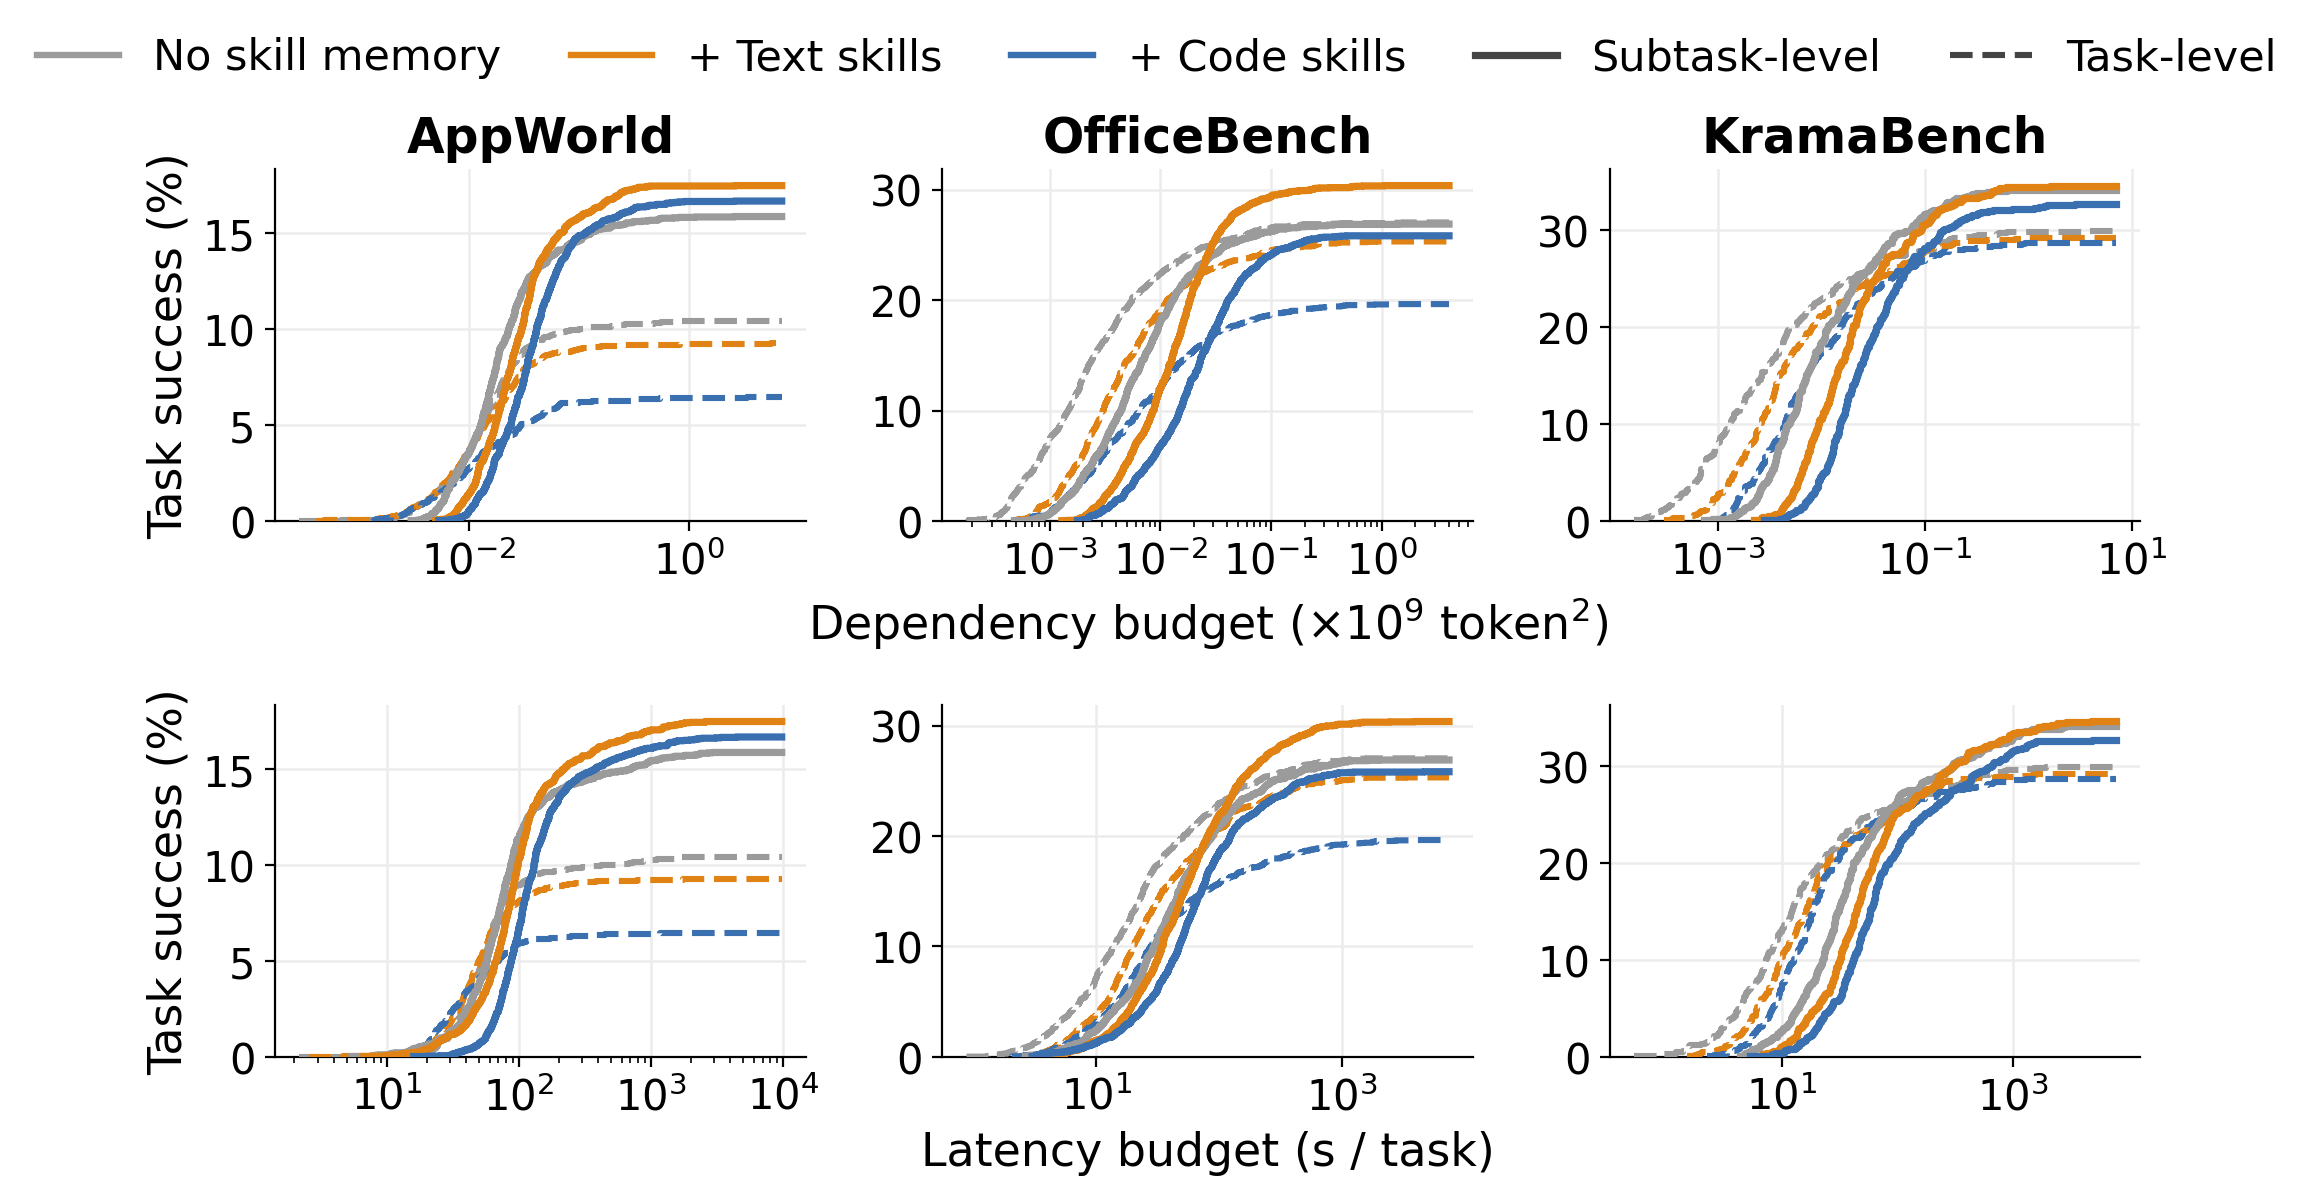

In [ ]:
# Fig q2_budget_per_bench (fig:budget-bench, App D): per-benchmark success-within-budget curves.
import os, pickle, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({
    'font.size': 16, 'axes.titlesize': 17.5, 'axes.labelsize': 16.5,
    'xtick.labelsize': 15, 'ytick.labelsize': 15, 'legend.fontsize': 15.5,
    'figure.dpi': 120, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#ececec', 'grid.linewidth': 0.9,
})
DATA_DIR = f'./{FOLDER}'
FIG_DIR = '../figures' if DATA_DIR.startswith('./') else 'figures'; os.makedirs(FIG_DIR, exist_ok=True)
BENCH_TOKENS = ['appworld', 'officebench', 'kramabench']
MODELS = ['qwen-3-235b-a22b-amazon', 'gpt-oss-120b-amazon', 'nemotron-3-super-120b-amazon',
          'qwen-3-4b-local', 'qwen-3-8b-local', 'qwen-3-14b-local', 'qwen-3-32b-local',
          'gemma-3-4b-local', 'gemma-3-12b-local', 'gemma-3-27b-local', 'gemini-3.1-pro-gcp']
CONDS = ['linear', 'linear_awm', 'linear_asi', 'subtask', 'subtask_awm', 'subtask_asi']
GRAY, TEXT_C, CODE_C = '#9b9b9b', '#e08214', '#3a6fb0'
FMT = {'': GRAY, '_awm': TEXT_C, '_asi': CODE_C}      # color = skill format
ARM = {'linear': (2.2, '--'), 'subtask': (2.6, '-')}  # line style = granularity


def _dependency(d):
    """MEM1 dependency = Sum_i (2*n_p + n_o)*n_o/2 over the task's LLM calls. 1e9 token²."""
    s = 0.0
    for c in d.get('llm_calls', []) or []:
        u = (c.get('response') or {}).get('usage') or {}
        np_, no_ = u.get('prompt_tokens', 0), u.get('completion_tokens', 0)
        s += (2 * np_ + no_) * no_ / 2.0
    return s / 1e9


def _read(p, tries=3):
    """Load a pkl; returns None for missing or unreadable files (retries transient NFS errors)."""
    for k in range(tries):
        try:
            with open(p, 'rb') as f:
                return pickle.load(f)
        except FileNotFoundError:
            return None
        except (OSError, EOFError, pickle.UnpicklingError) as e:
            if k == tries - 1:
                print(f'  ! treating as in-flight: {os.path.basename(p)} ({e})')
                return None
            time.sleep(1.0)


# one pass over the pkls: reduce each run to {task: (dependency, latency, success)}
RAW = {}
for B in BENCH_TOKENS:
    for c in CONDS:
        for M in MODELS:
            r = _read(f'{DATA_DIR}/{B}_{c}_{M}_{STAGE}.pkl')
            if r is None:
                RAW[(B, c, M)] = None; continue
            r = list(r.values()) if isinstance(r, dict) else r
            RAW[(B, c, M)] = {x['task_id']: (_dependency(x), x.get('wall_clock_seconds', 0),
                                             bool(x.get('success')))
                              for x in r if not x.get('errored') and x['task_id'] in COMMON[B]}

POOL = [M for M in MODELS
        if all(RAW[(B, c, M)] is not None and len(RAW[(B, c, M)]) == len(COMMON[B])
               for B in BENCH_TOKENS for c in CONDS)]
print(f'pooled models ({len(POOL)}/{len(MODELS)}):', POOL)
print('skipped (incomplete):', [M for M in MODELS if M not in POOL])

BENCH_NAMES = {'appworld': 'AppWorld', 'officebench': 'OfficeBench', 'kramabench': 'KramaBench'}
METRICS = [(0, 'Dependency budget ($\\times 10^9$ token$^2$)'),
           (1, 'Latency budget (s / task)')]
fig, axes = plt.subplots(2, 3, figsize=(10.6, 5.8))
for row, (mi, xlab) in enumerate(METRICS):
    for ci, B in enumerate(BENCH_TOKENS):
        ax = axes[row, ci]
        curves = []
        for arm, (lw, ls) in ARM.items():
            for suf, col in FMT.items():
                vals = [v for M in POOL for v in RAW[(B, f'{arm}{suf}', M)].values()]
                curves.append((col, ls, lw, vals))
        xmax = max(v[mi] for *_, vals in curves for v in vals if v[mi] > 0)
        for col, ls, lw, vals in curves:
            N = len(vals)
            sc = np.sort([v[mi] for v in vals if v[2] and v[mi] > 0])
            y = np.arange(1, len(sc) + 1) / N * 100
            ax.step(np.concatenate([sc, [xmax]]), np.concatenate([y, [y[-1]]]),
                    where='post', color=col, ls=ls, lw=lw, zorder=4)
        ax.set_xscale('log')
        ax.set_ylim(0, None)   # free y per benchmark, saturation levels differ
        if ci == 1:
            ax.set_xlabel(xlab)
        if row == 0:
            ax.set_title(BENCH_NAMES[B], fontweight='bold')
        if ci == 0:
            ax.set_ylabel('Task success (%)')
H = [Line2D([], [], color=GRAY, lw=2.3), Line2D([], [], color=TEXT_C, lw=2.3),
     Line2D([], [], color=CODE_C, lw=2.3),
     Line2D([], [], color='#444444', lw=2.6, ls='-'), Line2D([], [], color='#444444', lw=2.2, ls='--')]
fig.legend(H, ['No skill memory', '+ Text skills', '+ Code skills', 'Subtask-level', 'Task-level'],
           loc='upper center', ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.06),
           columnspacing=1.6, handlelength=1.9)
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/q2_budget_per_bench.png'); fig.savefig(f'{FIG_DIR}/q2_budget_per_bench.pdf')
plt.show()